# FedKG-Maint: Privacy-Preserving Federated Predictive Maintenance with KG-Grounded LLM Explanations

Runtime: Colab **T4 GPU** (Runtime > Change runtime type). Run the cells top to bottom.

* Default run (3 seeds, both datasets) is long (expect roughly 60-90 min on a T4; Cell 5 alone takes about 15-20 min). Set `quick=True` in Cell 1 for a short pipeline test.
* For real Azure results, put the five `PdM_*.csv` files in `/content/data/azure/` before running Cell 3.
* Any `[WARN] ... SYNTHETIC` line means a fallback dataset was used - do not report those numbers.
* Outputs (CSVs, figures, human-evaluation sheet) go to `/content/outputs`.

### Cell 1: Environment Setup & Library Installation

Installs dependencies, defines the global `CFG` (both datasets, models, FL, DP, explanations), seeds, device check and the memory helper. Torch is preinstalled on Colab so it is not reinstalled. Set `quick=True` for a short test run.

In [1]:
!pip install -q transformers accelerate networkx scipy requests pandas scikit-learn matplotlib

import os, gc, re, io, json, glob, time, zipfile, random, warnings, math, copy, subprocess
from collections import defaultdict
import numpy as np, pandas as pd, requests, networkx as nx
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import stats
from torch.nn.utils import parameters_to_vector
from sklearn.metrics import average_precision_score

warnings.filterwarnings('ignore')
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"torch {torch.__version__} | device = {device}" + (f" ({torch.cuda.get_device_name(0)})" if device == 'cuda' else ""))

# ----------------------------------------------------------------------------------
# Global configuration. Set quick=True for a ~5 minute smoke run (1 seed, few rounds).
# ----------------------------------------------------------------------------------
CFG = dict(
    quick=False,
    seeds=[0, 1, 2],                  # independent runs for mean/std + significance tests (use 5 if you have the time)
    # --- C-MAPSS (RUL regression): FD001-FD003 train, FD004 strict held-out factory ---
    train_factories=['FD001', 'FD002', 'FD003'], heldout='FD004',
    window=30, stride=2, rul_cap=125,
    # --- Azure PdM (failure within next N hours): factories = machine models, 'model4' strict held-out ---
    az_train=['model1', 'model2', 'model3'], az_heldout='model4',
    az_window=24, az_stride=6, az_eval_stride=3, az_horizon=24, az_split=(0.7, 0.8),   # temporal split: train / val / test
    az_machines=100, az_hours=24 * 150,         # only used if the real Azure CSVs are unavailable (synthetic fallback)
    # --- model + FL ---
    arch='lstm',                      # 'lstm' | 'transformer'
    hidden=48, layers=2, d_model=32, lr=1e-3, batch=256,
    rounds=16, local_epochs=2, ft_epochs=2, fedprox_mu=0.001, fedprox_mu_grid=[0.0001, 0.001, 0.01],   # mu is selected per task on the TRAIN factories
    # --- privacy ---
    dp_clip=1.0, dp_delta=1e-5, dp_sigma_full=0.01,
    dp_sigmas=[0.0, 0.005, 0.01, 0.02, 0.05, 0.1], dp_seeds=2,
    # --- extra experiments ---
    het_levels=[0.0, 0.5, 1.0], het_seeds=1, arch_seeds=2,    # het=1.0 natural non-IID, 0.0 fully IID
    # --- explanations ---
    risk_rul=30, n_explain=10,
    llm_backend='hf',                 # 'hf' (local Hugging Face) | 'api' (Anthropic API) | 'mock' (dry-run only)
    llm_model='Qwen/Qwen2.5-1.5B-Instruct',   # alternative: 'TinyLlama/TinyLlama-1.1B-Chat-v1.0'
    api_model='claude-haiku-5-5', max_new_tokens=160,
    data_dir='/content/data', out_dir='/content/outputs',
)
if CFG['quick']:
    CFG.update(seeds=[0], rounds=2, local_epochs=1, ft_epochs=1, stride=10, az_stride=24, az_eval_stride=24, az_machines=40, az_hours=24 * 50,
               dp_sigmas=[0.0, 0.01, 0.05], dp_seeds=1, fedprox_mu_grid=[0.001, 0.01], het_levels=[0.0, 1.0], arch_seeds=1, n_explain=3)
os.makedirs(CFG['data_dir'], exist_ok=True); os.makedirs(CFG['out_dir'], exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def free_mem():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

set_seed(0); free_mem()
print("Config ready:", {k: CFG[k] for k in ['seeds', 'train_factories', 'heldout', 'az_train', 'az_heldout', 'arch', 'rounds', 'local_epochs', 'llm_backend']})

torch 2.11.0+cu130 | device = cuda (Tesla T4)
Config ready: {'seeds': [0, 1, 2], 'train_factories': ['FD001', 'FD002', 'FD003'], 'heldout': 'FD004', 'az_train': ['model1', 'model2', 'model3'], 'az_heldout': 'model4', 'arch': 'lstm', 'rounds': 16, 'local_epochs': 2, 'llm_backend': 'hf'}


### Cell 2: NASA C-MAPSS Fetcher & Preprocessing

Downloads C-MAPSS from the S3 mirror (nested zips handled; synthetic fallback if offline), drops zero-variance channels by a local vote, scales **per factory** with local min-max, builds capped RUL targets and windows. **FD001-FD003 train, FD004 is the strict held-out factory.**

In [2]:
S3_URL = "https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip"
COLS = ['unit', 'cycle', 'op1', 'op2', 'op3'] + [f's{i}' for i in range(1, 22)]
FEATS = COLS[2:]                      # 3 operating settings + 21 sensors
RAW_DIR = os.path.join(CFG['data_dir'], 'cmapss_raw')
FACTORY_INFO = {'FD001': dict(units=100, regimes=1, fault_modes=1), 'FD002': dict(units=260, regimes=6, fault_modes=1),
                'FD003': dict(units=100, regimes=1, fault_modes=2), 'FD004': dict(units=249, regimes=6, fault_modes=2)}

# ------------------------------- download + extract ---------------------------------
def find_file(root, name):
    hits = glob.glob(os.path.join(root, '**', name), recursive=True)
    return hits[0] if hits else None

def download_cmapss():
    if find_file(RAW_DIR, 'train_FD001.txt') and find_file(RAW_DIR, 'RUL_FD004.txt'):
        return True
    os.makedirs(RAW_DIR, exist_ok=True)
    zpath = os.path.join(CFG['data_dir'], 'cmapss.zip')
    try:
        print("Downloading C-MAPSS from the AWS S3 mirror ...")
        with requests.get(S3_URL, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(zpath, 'wb') as f:
                for chunk in r.iter_content(chunk_size=1 << 20): f.write(chunk)
        with zipfile.ZipFile(zpath) as z: z.extractall(RAW_DIR)
        done = set()
        for _ in range(3):                                   # the archive may contain nested zips
            nested = [p for p in glob.glob(os.path.join(RAW_DIR, '**', '*.zip'), recursive=True) if p not in done]
            if not nested: break
            for p in nested:
                done.add(p)
                with zipfile.ZipFile(p) as z: z.extractall(p[:-4])
        return bool(find_file(RAW_DIR, 'train_FD001.txt'))
    except Exception as e:
        print(f"[WARN] Download/extract failed: {type(e).__name__}: {e}")
        return False

# ------------- synthetic fallback (same file format) so the notebook never dead-ends -------------
def make_synthetic_cmapss(seed=123):
    print("[WARN] Using SYNTHETIC C-MAPSS-like data (download unavailable). Numbers are NOT comparable to the real benchmark.")
    rng = np.random.RandomState(seed); os.makedirs(RAW_DIR, exist_ok=True)
    up, down = [2, 3, 4, 8, 9, 11, 13, 14, 15, 17], [7, 12, 20, 21]
    const = [1, 5, 6, 10, 16, 18, 19]
    base = rng.uniform(20, 600, 22); slope = rng.uniform(0.5, 3.0, 22)
    regimes = [(0, 0, 100), (10, .25, 100), (20, .7, 100), (25, .62, 60), (35, .84, 100), (42, .84, 40)]
    for fd, info in FACTORY_INFO.items():
        nreg, nfm = info['regimes'], info['fault_modes']
        reg_off = rng.uniform(-40, 40, (6, 22)) if nreg > 1 else np.zeros((6, 22))
        def engine(L, u):
            reg = rng.randint(0, nreg, L) if nreg > 1 else np.zeros(L, int)
            h = (np.arange(1, L + 1) / L) ** 1.6
            rows = np.zeros((L, 26)); rows[:, 0] = u; rows[:, 1] = np.arange(1, L + 1)
            for t in range(L):
                s = regimes[reg[t]] if nreg > 1 else (0, 0, 100)
                rows[t, 2:5] = [s[0] + rng.normal(0, .002), s[1] + rng.normal(0, .0003), s[2]]
            for k in range(1, 22):
                v = base[k] + reg_off[reg, k] + rng.normal(0, 0.8, L)
                if k in const: v = np.full(L, base[k])
                elif k in up: v = v + slope[k] * 12 * h * (1.0 if nfm == 1 or k != 8 else 1.4)
                elif k in down: v = v - slope[k] * 12 * h
                rows[:, 4 + k] = v
            return rows
        ntr = info['units']; tr = [engine(rng.randint(130, 360), u + 1) for u in range(ntr)]
        np.savetxt(os.path.join(RAW_DIR, f'train_{fd}.txt'), np.vstack(tr), fmt='%.5f')
        te, ruls = [], []
        for u in range(ntr):
            full = engine(rng.randint(130, 360), u + 1); cut = rng.randint(30, len(full) - 5)
            te.append(full[:cut]); ruls.append(len(full) - cut)
        np.savetxt(os.path.join(RAW_DIR, f'test_{fd}.txt'), np.vstack(te), fmt='%.5f')
        np.savetxt(os.path.join(RAW_DIR, f'RUL_{fd}.txt'), np.array(ruls), fmt='%d')

SYNTHETIC_CMAPSS = not download_cmapss()
if SYNTHETIC_CMAPSS: make_synthetic_cmapss()
read = lambda name: pd.read_csv(find_file(RAW_DIR, name), sep=r'\s+', header=None, names=COLS)

# ------------------ per-factory preprocessing: ALL statistics are computed locally ------------------
raw = {}
for fd in FACTORY_INFO:
    tr, te = read(f'train_{fd}.txt'), read(f'test_{fd}.txt')
    rul_te = np.loadtxt(find_file(RAW_DIR, f'RUL_{fd}.txt')).reshape(-1)
    tr['rul'] = np.minimum(tr.groupby('unit')['cycle'].transform('max') - tr['cycle'], CFG['rul_cap'])   # piecewise-linear RUL
    raw[fd] = dict(train=tr, test=te, rul_test=rul_te)

# Each TRAIN factory votes locally on which channels are non-constant; the agreed schema is the AND of the votes
# (1 bit per channel leaves each site). The held-out factory simply adopts the agreed schema.
local_masks = {fd: (raw[fd]['train'][FEATS].std().values > 1e-6) for fd in CFG['train_factories']}
KEEP_MASK = np.logical_and.reduce(list(local_masks.values()))
KEEP = [f for f, m in zip(FEATS, KEEP_MASK) if m]
print(f"Shared schema keeps {len(KEEP)}/{len(FEATS)} channels; dropped zero-variance: {[f for f in FEATS if f not in KEEP]}")

def make_windows(values, units, W, stride=1, last_only=False, y=None):
    """values (T,F) sorted by unit/cycle -> windows (N,W,F) ending at each step (front-padded by repeating the first row)."""
    Xs, ys = [], []
    for u in np.unique(units):
        m = units == u; v = values[m]
        pad = np.vstack([np.repeat(v[:1], W - 1, axis=0), v])
        win = np.lib.stride_tricks.sliding_window_view(pad, W, axis=0).transpose(0, 2, 1)   # (T,W,F)
        if last_only: Xs.append(win[-1:]); continue
        idx = np.arange(0, len(v), stride); Xs.append(win[idx])
        if y is not None: ys.append(y[m][idx])
    X = np.concatenate(Xs).astype(np.float32)
    return (X, None) if last_only or y is None else (X, np.concatenate(ys).astype(np.float32))

FAC = {}
for fd in FACTORY_INFO:
    tr, te = raw[fd]['train'], raw[fd]['test']
    lo, hi = tr[KEEP].min().values, tr[KEEP].max().values                  # LOCAL min-max statistics only
    scale = lambda df: ((df[KEEP].values - lo) / np.where(hi - lo < 1e-9, 1.0, hi - lo)).astype(np.float32)
    s_tr, s_te = scale(tr), scale(te)
    Xtr, ytr = make_windows(s_tr, tr['unit'].values, CFG['window'], CFG['stride'], y=tr['rul'].values)
    Xte, _ = make_windows(s_te, te['unit'].values, CFG['window'], last_only=True)
    FAC[fd] = dict(name=fd, heldout=(fd == CFG['heldout']), Xtr_base=Xtr, ytr=ytr, Xte_base=Xte,
                   yte=raw[fd]['rul_test'].astype(np.float32), scaled_train=s_tr, rul_train=tr['rul'].values,
                   lo=lo, hi=hi, n_units=tr['unit'].nunique(), n_rows=len(tr), **FACTORY_INFO[fd])
    assert len(Xte) == len(FAC[fd]['yte']), "test windows must match RUL file"

print("\nNon-IID factory partition (FD004 = strict held-out site):")
print(pd.DataFrame([{ 'factory': fd, 'role': 'HELD-OUT' if f['heldout'] else 'train', 'engines': f['n_units'], 'rows': f['n_rows'],
                      'train_windows': len(f['ytr']), 'regimes': f['regimes'], 'fault_modes': f['fault_modes'],
                      'mean_train_life': round(f['n_rows'] / f['n_units'], 1)} for fd, f in FAC.items()]).to_string(index=False))

free_mem()

Shared schema keeps 17/24 channels; dropped zero-variance: ['op3', 's1', 's5', 's10', 's16', 's18', 's19']

Non-IID factory partition (FD004 = strict held-out site):
factory     role  engines  rows  train_windows  regimes  fault_modes  mean_train_life
  FD001    train      100 20631          10341        1            1            206.3
  FD002    train      260 53759          26942        6            1            206.8
  FD003    train      100 24720          12387        1            2            247.2
  FD004 HELD-OUT      249 61249          30692        6            2            246.0


### Cell 3: Microsoft Azure PdM Fetcher & Preprocessing

Loads the real Azure CSVs (upload `PdM_*.csv` to `/content/data/azure/` or use a Kaggle token), otherwise generates synthetic Azure-style logs. Factories are the machine models (`model1`-`model3` train, **`model4` held-out**). Builds hourly features (telemetry, error counts, maintenance, time since replacement), failure-within-24h labels, local z-scoring and a temporal train/val/test split.

In [3]:
AZ_DIR = os.path.join(CFG['data_dir'], 'azure')
AZ_SENS = ['volt', 'rotate', 'pressure', 'vibration']; AZ_COMPS = [f'comp{i}' for i in range(1, 5)]; AZ_ERRS = [f'error{i}' for i in range(1, 6)]
AZ_FEATS = AZ_SENS + AZ_ERRS + [f'maint_{c}' for c in AZ_COMPS] + [f'tsr_{c}' for c in AZ_COMPS] + ['age']     # 4+5+4+4+1 = 18 channels
AZ_Z = [0, 1, 2, 3, 13, 14, 15, 16, 17]          # channels z-scored with LOCAL statistics (the rest are counts / indicators)
AZ_NBASE = len(AZ_FEATS); AZ_FACTORIES = CFG['az_train'] + [CFG['az_heldout']]
H_AHEAD, W_AZ = CFG['az_horizon'], CFG['az_window']

# ------------------------------- load real Azure CSVs, else Kaggle CLI, else synthetic -------------------------------
def synth_azure(n_machines, hours, seed=7):
    rng = np.random.RandomState(seed); t0 = pd.Timestamp('2015-01-01'); mu = np.array([170, 446, 100, 40.0]); sd = np.array([15, 52, 10, 5.0])
    eff = {1: (0, +1), 2: (1, -1), 3: (2, +1), 4: (3, +1)}          # failing component -> (sensor index, drift sign)
    machines = pd.DataFrame({'machineID': np.arange(1, n_machines + 1), 'model': rng.choice(['model1', 'model2', 'model3', 'model4'], n_machines, p=[.25, .25, .25, .25]),
                             'age': rng.randint(0, 20, n_machines)})
    tel, err, fail, mnt = [], [], [], []; ts = t0 + pd.to_timedelta(np.arange(hours), unit='h'); ar = np.arange(hours)
    for _, mrow in machines.iterrows():
        m = int(mrow.machineID); off = (int(mrow.model[-1]) - 2.5) * 0.25                    # model-specific operating regime -> non-IID
        X = rng.normal(mu + off * sd, sd, (hours, 4))
        for f in np.sort(rng.choice(np.arange(60, hours - 3), rng.randint(2, 5), replace=False)):
            c = rng.randint(1, 5); si, sg = eff[c]
            X[:, si] += sg * 1.4 * sd[si] * np.clip(1 - (f - ar) / 36.0, 0, 1) * (ar <= f)
            fail.append({'datetime': ts[f], 'machineID': m, 'failure': f'comp{c}'}); mnt.append({'datetime': ts[min(f + 1, hours - 1)], 'machineID': m, 'comp': f'comp{c}'})
            for h in range(max(0, f - 48), f):
                if rng.rand() < 0.10: err.append({'datetime': ts[h], 'machineID': m, 'errorID': f'error{c}'})
        for h in np.where(rng.rand(hours) < 0.004)[0]: err.append({'datetime': ts[h], 'machineID': m, 'errorID': f'error{rng.randint(1, 6)}'})
        for h in rng.choice(hours, 3, replace=False): mnt.append({'datetime': ts[h], 'machineID': m, 'comp': f'comp{rng.randint(1, 5)}'})
        tel.append(pd.DataFrame({'datetime': ts, 'machineID': m, 'volt': X[:, 0], 'rotate': X[:, 1], 'pressure': X[:, 2], 'vibration': X[:, 3]}))
    return dict(telemetry=pd.concat(tel, ignore_index=True), errors=pd.DataFrame(err), maint=pd.DataFrame(mnt), failures=pd.DataFrame(fail), machines=machines)

def fetch_azure():
    names = ['telemetry', 'errors', 'maint', 'failures', 'machines']; files = {n: os.path.join(AZ_DIR, f'PdM_{n}.csv') for n in names}
    os.makedirs(AZ_DIR, exist_ok=True)
    if not all(os.path.exists(p) for p in files.values()):
        try:                                                        # works only if the user has a Kaggle token configured
            if os.path.exists(os.path.expanduser('~/.kaggle/kaggle.json')) or os.environ.get('KAGGLE_KEY'):
                subprocess.run(['kaggle', 'datasets', 'download', '-d', 'arnabbiswas1/microsoft-azure-predictive-maintenance', '-p', AZ_DIR, '--unzip'],
                               check=True, timeout=300, capture_output=True)
        except Exception as e:
            print(f"[INFO] Kaggle download unavailable ({type(e).__name__}).")
    if all(os.path.exists(p) for p in files.values()):
        d = {n: pd.read_csv(p) for n, p in files.items()}
        for n in ['telemetry', 'errors', 'maint', 'failures']: d[n]['datetime'] = pd.to_datetime(d[n]['datetime'])
        print("Loaded the REAL Azure PdM CSVs."); return d, False
    print("[WARN] Using SYNTHETIC Azure-style logs (no Kaggle credentials / CSVs in %s). Upload the 5 PdM_*.csv files there for real results." % AZ_DIR)
    return synth_azure(CFG['az_machines'], CFG['az_hours']), True

AZURE, AZURE_SYNTHETIC = fetch_azure()
for _n, _df in AZURE.items():                                      # tolerate stray whitespace / dtype differences in the CSVs
    _df.columns = [str(c).strip() for c in _df.columns]
    if 'machineID' in _df.columns: _df['machineID'] = pd.to_numeric(_df['machineID'], errors='coerce')
    AZURE[_n] = _df.dropna(subset=['machineID']).assign(machineID=lambda d: d['machineID'].astype(int)) if 'machineID' in _df.columns else _df
AZURE['machines']['model'] = AZURE['machines']['model'].astype(str).str.strip().str.lower()
_have = set(AZURE['telemetry']['machineID'].unique())
print("Azure machines per model (with telemetry):", {m: int(g['machineID'].isin(_have).sum()) for m, g in AZURE['machines'].groupby('model')})
for _fd in CFG['az_train'] + [CFG['az_heldout']]:
    if not AZURE['machines'].loc[AZURE['machines']['model'] == _fd, 'machineID'].isin(_have).any():
        raise ValueError(f"No machines with telemetry for factory '{_fd}'. Models found in PdM_machines.csv: {sorted(AZURE['machines']['model'].unique())}; "
                         f"machine IDs in telemetry: {len(_have)}. Check that the 5 CSVs are the right files, or change CFG['az_train'] / CFG['az_heldout'].")
T0 = AZURE['telemetry']['datetime'].min().floor('h'); H_TOT = int((AZURE['telemetry']['datetime'].max() - T0) / pd.Timedelta(hours=1)) + 1
CUT1, CUT2 = int(CFG['az_split'][0] * H_TOT), int(CFG['az_split'][1] * H_TOT)        # schema-level agreement on the temporal split

# ------------------------------- per-machine hourly feature rows + labels -------------------------------
def machine_rows(tel_g, err_g, mnt_g, fail_g, age):
    X = np.zeros((H_TOT, AZ_NBASE), np.float32); ar = np.arange(H_TOT)
    hi = np.rint((tel_g['datetime'] - T0) / pd.Timedelta(hours=1)).astype(int).values; ok = (hi >= 0) & (hi < H_TOT)
    tel = np.full((H_TOT, 4), np.nan); tel[hi[ok]] = tel_g[AZ_SENS].values[ok]
    X[:, :4] = pd.DataFrame(tel).ffill().bfill().values
    if len(err_g):
        eh = np.rint((err_g['datetime'] - T0) / pd.Timedelta(hours=1)).astype(int).values; ec = err_g['errorID'].str[5:].astype(int).values - 1
        k = (eh >= 0) & (eh < H_TOT); np.add.at(X, (eh[k], 4 + ec[k]), 1)
    for j, c in enumerate(AZ_COMPS):
        ev = np.zeros(H_TOT, bool)
        if len(mnt_g):
            mh = np.rint((mnt_g.loc[mnt_g['comp'] == c, 'datetime'] - T0) / pd.Timedelta(hours=1)).astype(int).values; mh = mh[(mh >= 0) & (mh < H_TOT)]; ev[mh] = True
        X[:, 9 + j] = ev; last = np.maximum.accumulate(np.where(ev, ar, -1)); X[:, 13 + j] = np.log1p(np.where(last >= 0, ar - last, ar + 1) / 24.0)
    X[:, 17] = age
    Y = np.zeros((H_TOT, 5), np.float32)                           # [any, comp1..comp4]: failure within the next N hours
    for _, r in fail_g.iterrows():
        fh = int(round((r['datetime'] - T0) / pd.Timedelta(hours=1)))
        if 0 <= fh < H_TOT: c = int(r['failure'][4:]); Y[max(0, fh - H_AHEAD):fh + 1, c] = 1; Y[max(0, fh - H_AHEAD):fh + 1, 0] = 1
    return X, Y

grp = lambda df: {m: g for m, g in df.groupby('machineID')}
G_T, G_E, G_M, G_F = grp(AZURE['telemetry']), grp(AZURE['errors']), grp(AZURE['maint']), grp(AZURE['failures'])
empty = lambda df: df.iloc[0:0]
AZR = {}
for fd in AZ_FACTORIES:                                           # factory = machines of one model
    mach = AZURE['machines'][AZURE['machines']['model'] == fd]; Xs, Ys, mids = [], [], []
    for _, r in mach.iterrows():
        m = int(r['machineID'])
        if m not in G_T: continue
        X, Y = machine_rows(G_T[m], G_E.get(m, empty(AZURE['errors'])), G_M.get(m, empty(AZURE['maint'])), G_F.get(m, empty(AZURE['failures'])), r['age'])
        Xs.append(X); Ys.append(Y); mids.append(m)
    tr_rows = np.concatenate([x[:CUT1] for x in Xs])                # LOCAL statistics from this factory's own training period only
    mu, sd = tr_rows[:, AZ_Z].mean(0), tr_rows[:, AZ_Z].std(0) + 1e-6
    for x in Xs: x[:, AZ_Z] = (x[:, AZ_Z] - mu) / sd
    AZR[fd] = dict(mids=mids, X=Xs, Y=Ys, mu=mu, sd=sd)
del G_T, G_E, G_M, G_F, AZURE['telemetry']; free_mem()

def az_windows(Xm, Ym, lo, hi, stride):
    """windows ending at hours t in [lo, hi) (front-padding when t < W-1); returns X, y(any), y(per component), t"""
    pad = np.vstack([np.repeat(Xm[:1], W_AZ - 1, axis=0), Xm]); ts = np.arange(lo, hi, stride)
    win = np.lib.stride_tricks.sliding_window_view(pad, W_AZ, axis=0)[ts].transpose(0, 2, 1)
    return win.astype(np.float32), Ym[ts, 0], Ym[ts, 1:], ts

AZF = {}
for fd in AZ_FACTORIES:
    r = AZR[fd]; held = (fd == CFG['az_heldout']); parts = {k: [] for k in ['Xtr', 'ytr', 'Xva', 'yva', 'Xte', 'yte', 'ytec', 'tte', 'mte']}
    for mid, Xm, Ym in zip(r['mids'], r['X'], r['Y']):
        if not held:
            a = az_windows(Xm, Ym, 0, CUT1 - H_AHEAD, CFG['az_stride']); parts['Xtr'].append(a[0]); parts['ytr'].append(a[1])
            a = az_windows(Xm, Ym, CUT1, CUT2 - H_AHEAD, CFG['az_stride']); parts['Xva'].append(a[0]); parts['yva'].append(a[1])
            a = az_windows(Xm, Ym, CUT2, H_TOT, CFG['az_eval_stride'])
        else:
            a = az_windows(Xm, Ym, 0, H_TOT, CFG['az_eval_stride'])            # the held-out factory is evaluated on its whole history
        parts['Xte'].append(a[0]); parts['yte'].append(a[1]); parts['ytec'].append(a[2]); parts['tte'].append(a[3]); parts['mte'].append(np.full(len(a[1]), mid))
    cat = lambda k: np.concatenate(parts[k]) if parts[k] else None
    AZF[fd] = dict(name=fd, heldout=held, Xtr_base=cat('Xtr'), ytr=cat('ytr'), Xva_base=cat('Xva'), yva=cat('yva'), Xte_base=cat('Xte'), yte=cat('yte'),
                   yte_comp=cat('ytec'), te_t=cat('tte'), te_mid=cat('mte'), n_machines=len(r['mids']))
print(f"Azure PdM: {H_TOT} hourly steps, split train<{CUT1}h | val<{CUT2}h | test afterwards; label = failure within next {H_AHEAD}h")
print(pd.DataFrame([{'factory': fd, 'role': 'HELD-OUT' if f['heldout'] else 'train', 'machines': f['n_machines'],
                     'train_windows': 0 if f['Xtr_base'] is None else len(f['ytr']), 'train_pos_rate': np.nan if f['ytr'] is None else round(float(f['ytr'].mean()), 4),
                     'test_windows': len(f['yte']), 'test_pos_rate': round(float(f['yte'].mean()), 4)} for fd, f in AZF.items()]).to_string(index=False))
free_mem()

Loaded the REAL Azure PdM CSVs.
Azure machines per model (with telemetry): {'model1': 16, 'model2': 17, 'model3': 35, 'model4': 32}
Azure PdM: 8761 hourly steps, split train<6132h | val<7008h | test afterwards; label = failure within next 24h
factory     role  machines  train_windows  train_pos_rate  test_windows  test_pos_rate
 model1    train        16          16288          0.0376          9360         0.0317
 model2    train        17          17306          0.0328          9945         0.0282
 model3    train        35          35630          0.0222         20475         0.0145
 model4 HELD-OUT        32              0             NaN         93472         0.0165


### Cell 4: Maintenance Knowledge Graphs (C-MAPSS + Azure)

Shared ontology (`Machine`, `Component`, `Sensor`, `ErrorCode`, `FailureMode`, `Action`). Each factory builds its **own local** NetworkX graph from its own data (thresholds, effect sizes, error-code lifts) and enriches it with domain rules. KG-guided channels are fed to the model.

In [4]:
# ------------------------------- shared ontology (agreed by ALL factories, both datasets) -------------------------------
ONTOLOGY = {
    "entities": {"Machine": ["id", "factory"], "Component": ["name"], "Sensor": ["name", "description"], "ErrorCode": ["name"],
                 "FailureMode": ["name", "component"], "Action": ["name", "priority", "description"]},
    "relations": {"HAS_SENSOR": ["Machine", "Sensor"], "HAS_COMPONENT": ["Machine", "Component"], "INDICATES": ["Sensor", "FailureMode"],
                  "PRECEDES": ["ErrorCode", "FailureMode"], "AFFECTS": ["FailureMode", "Component"], "REMEDIATED_BY": ["FailureMode", "Action"]},
}
json.dump(ONTOLOGY, open(os.path.join(CFG['out_dir'], 'ontology.json'), 'w'), indent=2)

# ============================ A) C-MAPSS knowledge graphs ============================
SENSOR_META = {   # column -> (name, description, expected drift with degradation: +1 rises, -1 falls)
    's2': ('T24', 'LPC outlet temperature', +1), 's3': ('T30', 'HPC outlet temperature', +1), 's4': ('T50', 'LPT outlet temperature', +1),
    's7': ('P30', 'HPC outlet pressure', -1), 's8': ('Nf', 'physical fan speed', +1), 's9': ('Nc', 'physical core speed', +1),
    's11': ('Ps30', 'HPC outlet static pressure', +1), 's12': ('phi', 'fuel flow / Ps30 ratio', -1), 's13': ('NRf', 'corrected fan speed', +1),
    's14': ('NRc', 'corrected core speed', +1), 's15': ('BPR', 'bypass ratio', +1), 's17': ('htBleed', 'bleed enthalpy', +1),
    's20': ('W31', 'HPT coolant bleed', -1), 's21': ('W32', 'LPT coolant bleed', -1)}
# Domain-knowledge enrichment (illustrative priors from published C-MAPSS degradation trends): sensor -> failure mode
DOMAIN_RULES = {'HPC_DEGRADATION': ['s2', 's3', 's4', 's7', 's9', 's11', 's12', 's14', 's17', 's20', 's21'], 'FAN_DEGRADATION': ['s8', 's13', 's15']}
FAULT_COMPONENT = {'HPC_DEGRADATION': 'HPC', 'FAN_DEGRADATION': 'FAN'}
ACTIONS = {
    'HPC_DEGRADATION': [('INSPECT_HPC_BLADES', 1, 'borescope inspection of HPC blades for fouling or erosion'),
                        ('SCHEDULE_HPC_WASH', 2, 'schedule an HPC wash to restore compressor efficiency'),
                        ('CHECK_BLEED_VALVES', 3, 'verify bleed and coolant valve operation')],
    'FAN_DEGRADATION': [('INSPECT_FAN_BLADES', 1, 'visual and borescope inspection of fan blades'),
                        ('BALANCE_FAN_ROTOR', 2, 'check fan rotor balance and speed sensors')]}
SENSOR_NAMES = [v[0] for v in SENSOR_META.values()]; FAULT_MODES = list(DOMAIN_RULES); ACTION_NAMES = [a[0] for acts in ACTIONS.values() for a in acts]
N_BASE = len(KEEP); KG_GROUPS = {fm: [(KEEP.index(c), SENSOR_META[c][2]) for c in cols if c in KEEP] for fm, cols in DOMAIN_RULES.items()}

def kg_channels(X):
    """KG-guided features: per failure mode, mean degradation-direction value of its linked sensors (shared schema rules)."""
    chans = []
    for fm in FAULT_MODES:
        idx = [i for i, _ in KG_GROUPS[fm]]; sg = np.array([s for _, s in KG_GROUPS[fm]], dtype=np.float32)
        v = np.where(sg > 0, X[:, :, idx], 1.0 - X[:, :, idx]); chans.append(v.mean(-1, keepdims=True))
    return np.concatenate(chans, axis=-1).astype(np.float32)

for fd, f in FAC.items():
    f['Xtr'] = np.concatenate([f['Xtr_base'], kg_channels(f['Xtr_base'])], -1); f['Xte'] = np.concatenate([f['Xte_base'], kg_channels(f['Xte_base'])], -1)
N_ALL = N_BASE + len(FAULT_MODES)

def build_cmapss_kg(fd):
    f = FAC[fd]; G = nx.MultiDiGraph(name=f'KG_{fd}', factory=fd); x, rul = f['scaled_train'], f['rul_train']
    healthy, late = rul >= CFG['rul_cap'], rul <= CFG['risk_rul']; fms = FAULT_MODES[:f['fault_modes']]
    for fm in fms:
        G.add_node(fm, type='FailureMode', component=FAULT_COMPONENT[fm]); G.add_node(FAULT_COMPONENT[fm], type='Component'); G.add_edge(fm, FAULT_COMPONENT[fm], rel='AFFECTS')
        for (an, pr, desc) in ACTIONS[fm]:
            G.add_node(an, type='Action', priority=pr, description=desc); G.add_edge(fm, an, rel='REMEDIATED_BY', priority=pr)
    used = set()
    for fm in fms:
        for col in DOMAIN_RULES[fm]:
            if col not in KEEP: continue
            name, desc, direction = SENSOR_META[col]; i = KEEP.index(col)
            h_mean, l_mean = (x[healthy, i].mean() if healthy.any() else 0.0), (x[late, i].mean() if late.any() else 1.0)
            corr = float(np.corrcoef(x[:, i], rul)[0, 1]) if x[:, i].std() > 0 else 0.0
            if col not in used: G.add_node(name, type='Sensor', column=col, description=desc, idx=i); used.add(col)
            G.add_edge(name, fm, rel='INDICATES', direction=direction, threshold=float(0.5 * (h_mean + l_mean)), local_corr=round(corr, 3),
                       consistent_with_data=bool(np.sign(corr) == -direction))
    for u in range(1, f['n_units'] + 1):
        mid = f'{fd}_E{u:03d}'; G.add_node(mid, type='Machine', factory=fd)
        for col in used: G.add_edge(mid, SENSOR_META[col][0], rel='HAS_SENSOR')
        for c in {FAULT_COMPONENT[fm] for fm in fms}: G.add_edge(mid, c, rel='HAS_COMPONENT')
    return G
KGS = {fd: build_cmapss_kg(fd) for fd in FAC}

# ============================ B) Azure knowledge graphs (built from each factory's own TRAIN period) ============================
AZ_FAULTS = [f'FAIL_{c.upper()}' for c in AZ_COMPS]
AZ_ACTIONS = {f'FAIL_{c.upper()}': [(f'REPLACE_{c.upper()}', 1, f'replace {c}'), (f'INSPECT_{c.upper()}', 2, f'inspect {c} and check its recent error codes')] for c in AZ_COMPS}
AZ_KGW = {}

def build_azure_kg(fd):
    r = AZR[fd]; cut = CUT1 - H_AHEAD; Xs, Ys, Ps = [], [], []
    for X, Y in zip(r['X'], r['Y']):
        cs = np.cumsum(X[:, 4:9], 0); prev = np.zeros_like(cs); prev[24:] = cs[:-24]
        Xs.append(X[:cut]); Ys.append(Y[:cut]); Ps.append(((cs - prev) > 0)[:cut])        # error code seen in the last 24h
    Xs, Ys, Ps = np.concatenate(Xs), np.concatenate(Ys), np.concatenate(Ps); base = Ys[:, 0] == 0
    G = nx.MultiDiGraph(name=f'KG_{fd}', factory=fd); Wk = np.zeros((AZ_NBASE, len(AZ_COMPS)), np.float32)
    for s in AZ_SENS: G.add_node(s, type='Sensor', description=s)
    for e in AZ_ERRS: G.add_node(e, type='ErrorCode')
    for k, c in enumerate(AZ_COMPS):
        fm = AZ_FAULTS[k]; G.add_node(c, type='Component'); G.add_node(fm, type='FailureMode', component=c); G.add_edge(fm, c, rel='AFFECTS')
        for (an, pr, desc) in AZ_ACTIONS[fm]: G.add_node(an, type='Action', priority=pr, description=desc); G.add_edge(fm, an, rel='REMEDIATED_BY', priority=pr)
        pos = Ys[:, 1 + k] == 1; G.nodes[fm]['n_pos_hours_local'] = int(pos.sum())
        if pos.sum() >= 20:
            for si, s in enumerate(AZ_SENS):
                d = float(Xs[pos, si].mean() - Xs[base, si].mean())
                if abs(d) >= 0.15: G.add_edge(s, fm, rel='INDICATES', direction=int(np.sign(d)), effect=d); Wk[si, k] = d
            p0 = pos.mean()
            for ei, e in enumerate(AZ_ERRS):
                pe = Ps[:, ei]; n_pos_e = int((pos & pe).sum())
                if pe.sum() >= 5 and n_pos_e >= 5:
                    lift = float((pos[pe].mean() + 1e-4) / (p0 + 1e-4))
                    if lift > 1.2: G.add_edge(e, fm, rel='PRECEDES', lift=lift, support=n_pos_e); Wk[4 + ei, k] = min(np.log(lift), 3.0)
    for m in r['mids']:
        mid = f'{fd}_M{m:03d}'; G.add_node(mid, type='Machine', factory=fd)
        for s in AZ_SENS: G.add_edge(mid, s, rel='HAS_SENSOR')
        for c in AZ_COMPS: G.add_edge(mid, c, rel='HAS_COMPONENT')
    AZ_KGW[fd] = Wk / (np.abs(Wk).sum(0, keepdims=True) + 1e-6)
    return G
AZ_KGS = {fd: build_azure_kg(fd) for fd in AZ_FACTORIES}

def az_kg_channels(X, Wk): return np.einsum('nwf,fk->nwk', X, Wk).astype(np.float32)
for fd, f in AZF.items():
    for a, b in [('Xtr', 'Xtr_base'), ('Xva', 'Xva_base'), ('Xte', 'Xte_base')]:
        f[a] = None if f[b] is None else np.concatenate([f[b], az_kg_channels(f[b], AZ_KGW[fd])], -1)
AZ_NALL = AZ_NBASE + len(AZ_COMPS)
del AZR; free_mem()

# ------------------------------- summary -------------------------------
rows = []
for ds, graphs in [('C-MAPSS', KGS), ('Azure', AZ_KGS)]:
    for fd, G in graphs.items():
        cnt = defaultdict(int); rel = defaultdict(int)
        for _, d in G.nodes(data=True): cnt[d['type']] += 1
        for _, _, d in G.edges(data=True): rel[d['rel']] += 1
        rows.append(dict(dataset=ds, factory=fd, nodes=G.number_of_nodes(), edges=G.number_of_edges(), machines=cnt['Machine'], sensors=cnt['Sensor'],
                         error_codes=cnt['ErrorCode'], failure_modes=cnt['FailureMode'], actions=cnt['Action'], INDICATES=rel['INDICATES'], PRECEDES=rel['PRECEDES']))
print(pd.DataFrame(rows).to_string(index=False))
def show_triples(G, rel, n=2):
    out = [(u, v, d) for u, v, d in G.edges(data=True) if d['rel'] == rel][:n]
    for u, v, d in out: print(f"  ({u}) -[{rel} {', '.join(f'{k}={round(x, 2) if isinstance(x, float) else x}' for k, x in d.items() if k != 'rel')}]-> ({v})")
print("\nExample local triples:"); show_triples(KGS['FD001'], 'INDICATES', 1); show_triples(AZ_KGS[CFG['az_train'][0]], 'INDICATES', 2)
show_triples(AZ_KGS[CFG['az_train'][0]], 'PRECEDES', 2); show_triples(AZ_KGS[CFG['az_train'][0]], 'REMEDIATED_BY', 1)
print(f"\nModel input channels: C-MAPSS {N_BASE} + {len(FAULT_MODES)} KG = {N_ALL}; Azure {AZ_NBASE} + {len(AZ_COMPS)} KG = {AZ_NALL}")
free_mem()

dataset factory  nodes  edges  machines  sensors  error_codes  failure_modes  actions  INDICATES  PRECEDES
C-MAPSS   FD001    116   1215       100       11            0              1        3         11         0
C-MAPSS   FD002    276   3135       260       11            0              1        3         11         0
C-MAPSS   FD003    123   1621       100       14            0              2        5         14         0
C-MAPSS   FD004    272   4005       249       14            0              2        5         14         0
  Azure  model1     41    164        16        4            5              4        8          5        19
  Azure  model2     42    171        17        4            5              4        8          6        17
  Azure  model3     60    307        35        4            5              4        8          3        12
  Azure  model4     57    285        32        4            5              4        8          4        13

Example local triples:
  (T24) -[IND

### Cell 5: Federated Learning Framework

LSTM or Transformer; Centralized and Local-only references; FedAvg and FedProx; personalized FedAvg+FT; DP-ready client updates; identical epoch budget; evaluation on every factory including the held-out one (RMSE / NASA score for C-MAPSS, PR-AUC / F1 for Azure).

In [5]:
TASK = {'cmapss': dict(train=CFG['train_factories'], held=CFG['heldout'], names=('RMSE', 'NASA score'), lower_is_better=True, win=CFG['window'], nb=N_BASE, na=N_ALL, data=FAC),
        'azure': dict(train=CFG['az_train'], held=CFG['az_heldout'], names=('PR-AUC', 'F1'), lower_is_better=False, win=CFG['az_window'], nb=AZ_NBASE, na=AZ_NALL, data=AZF)}
TOTAL_EPOCHS = CFG['rounds'] * CFG['local_epochs']      # identical compute budget for every method
CAP = CFG['rul_cap']

# ------------------------------- models: LSTM or small Transformer encoder -------------------------------
class SeqModel(nn.Module):
    def __init__(self, d_in, win, arch):
        super().__init__(); self.arch = arch
        if arch == 'lstm':
            self.enc = nn.LSTM(d_in, CFG['hidden'], CFG['layers'], batch_first=True); out = CFG['hidden']
        else:
            dm = CFG['d_model']; self.inp = nn.Linear(d_in, dm); self.pos = nn.Parameter(torch.randn(1, win, dm) * 0.02)
            self.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(dm, 4, 2 * dm, dropout=0.0, batch_first=True), 2, enable_nested_tensor=False); out = dm
        self.head = nn.Sequential(nn.Linear(out, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        h = self.enc(x)[0][:, -1] if self.arch == 'lstm' else self.enc(self.inp(x) + self.pos).mean(1)
        return self.head(h).squeeze(-1)

def new_model(task, use_kg, arch=None):
    T = TASK[task]; return SeqModel(T['na'] if use_kg else T['nb'], T['win'], arch or CFG['arch']).to(device)
def n_params(m): return sum(p.numel() for p in m.parameters())
def set_params(model, vec):                                  # COPY into the parameters (vector_to_parameters would alias the vector)
    i = 0
    with torch.no_grad():
        for p in model.parameters(): n = p.numel(); p.copy_(vec[i:i + n].view_as(p)); i += n

# ------------------------------- GPU-resident data -------------------------------
_GPU = {}
def _t(a): return torch.tensor(np.ascontiguousarray(a), dtype=torch.float32).to(device)
def get_data(task, fd, use_kg):
    key = (task, fd, use_kg)
    if key not in _GPU:
        T = TASK[task]; n = T['na'] if use_kg else T['nb']; f = T['data'][fd]; d = {}
        if f.get('Xtr') is not None: d['Xtr'] = _t(f['Xtr'][:, :, :n]); d['ytr'] = _t(f['ytr'] / CAP if task == 'cmapss' else f['ytr'])
        if f.get('Xva') is not None: d['Xva'] = _t(f['Xva'][:, :, :n]); d['yva'] = f['yva']
        d['Xte'] = _t(f['Xte'][:, :, :n]); d['yte'] = f['yte']; _GPU[key] = d
    return _GPU[key]

def pos_weight(y):
    p = float(y.float().mean()); return float(min(max((1 - p) / max(p, 1e-4), 1.0), 20.0))

def train_epochs(model, X, y, epochs, task, pw=1.0, mu=0.0, ref=None):
    """Local training. mu>0 adds the FedProx proximal gradient mu*(w - w_global)."""
    opt = torch.optim.Adam(model.parameters(), lr=CFG['lr']); model.train(); n = X.shape[0]; params = list(model.parameters())
    pwt = torch.tensor(pw, device=X.device)
    for _ in range(epochs):
        perm = torch.randperm(n, device=X.device)
        for i in range(0, n, CFG['batch']):
            idx = perm[i:i + CFG['batch']]; out = model(X[idx])
            loss = F.mse_loss(out, y[idx]) if task == 'cmapss' else F.binary_cross_entropy_with_logits(out, y[idx], pos_weight=pwt)
            opt.zero_grad(set_to_none=True); loss.backward()
            if mu > 0:
                for p, g in zip(params, ref): p.grad.add_(p.data - g, alpha=mu)
            opt.step()

# ------------------------------- metrics -------------------------------
def nasa_score(pred, true):
    d = pred - true; return float(np.sum(np.where(d < 0, np.exp(-d / 13.0) - 1, np.exp(d / 10.0) - 1)))
@torch.no_grad()
def raw_out(model, X):
    model.eval(); return torch.cat([model(X[i:i + 8192]).float() for i in range(0, X.shape[0], 8192)]).cpu().numpy()
def best_threshold(p, y):
    if y.sum() == 0: return 0.5
    best, bt = -1, 0.5
    for t in np.unique(np.quantile(p, np.linspace(0.80, 0.9995, 80))):
        pr = p >= t; tp = (pr & (y == 1)).sum(); f1 = 2 * tp / max(pr.sum() + y.sum(), 1)
        if f1 > best: best, bt = f1, float(t)
    return bt
def az_metrics(p, y, thr):
    if y.sum() == 0: return 0.0, 0.0
    pr = p >= thr; return float(average_precision_score(y, p)), float(2 * (pr & (y == 1)).sum() / max(pr.sum() + y.sum(), 1))

def evaluate(model, task, use_kg, thr=None, val_fds=None):
    """-> ({factory: (primary, secondary)}, threshold). cmapss: (RMSE, NASA). azure: (PR-AUC, F1 at a validation-chosen threshold)."""
    T = TASK[task]; fds = T['train'] + [T['held']]; out = {}
    if task == 'cmapss':
        for fd in fds:
            d = get_data(task, fd, use_kg); p = (raw_out(model, d['Xte']) * CAP).clip(0, CAP)
            out[fd] = (float(np.sqrt(np.mean((p - d['yte']) ** 2))), nasa_score(p, d['yte']))
        return out, None
    sig = lambda z: 1 / (1 + np.exp(-z))
    if thr is None:                                                    # threshold from the validation period of the TRAIN factories only
        ps, ys = zip(*[(sig(raw_out(model, get_data(task, fd, use_kg)['Xva'])), get_data(task, fd, use_kg)['yva']) for fd in (val_fds or T['train'])])
        thr = best_threshold(np.concatenate(ps), np.concatenate(ys))
    for fd in fds: d = get_data(task, fd, use_kg); out[fd] = az_metrics(sig(raw_out(model, d['Xte'])), d['yte'], thr)
    return out, thr
def heldout_primary(model, task, use_kg):
    T = TASK[task]; d = get_data(task, T['held'], use_kg); z = raw_out(model, d['Xte'])
    return float(np.sqrt(np.mean(((z * CAP).clip(0, CAP) - d['yte']) ** 2))) if task == 'cmapss' else az_metrics(1 / (1 + np.exp(-z)), d['yte'], 0.5)[0]

# ------------------------------- client data (optionally with controlled heterogeneity) -------------------------------
def client_data(task, use_kg, clients, het, seed):
    base = {fd: get_data(task, fd, use_kg) for fd in clients}
    if het >= 1.0: return {fd: (base[fd]['Xtr'], base[fd]['ytr']) for fd in clients}
    g = torch.Generator().manual_seed(seed + 17); Xp = torch.cat([base[fd]['Xtr'] for fd in clients]); yp = torch.cat([base[fd]['ytr'] for fd in clients]); out = {}
    for fd in clients:                          # het in [0,1]: fraction of a client's data that is its own; the rest is drawn from the pooled data (0 = IID)
        n = base[fd]['Xtr'].shape[0]; own = int(round(het * n)); oi = torch.randperm(n, generator=g)[:own].to(device); pi = torch.randint(0, Xp.shape[0], (n - own,), generator=g).to(device)
        out[fd] = (torch.cat([base[fd]['Xtr'][oi], Xp[pi]]), torch.cat([base[fd]['ytr'][oi], yp[pi]]))
    del Xp, yp; return out

# ------------------------------- federated training: FedAvg / FedProx (+ optional DP) -------------------------------
RUN_CACHE = {}
MU = {t: CFG['fedprox_mu'] for t in TASK}          # FedProx proximal weight per task (selected below)
def fed_train(task, strategy, seed, use_kg=True, sigma=0.0, clients=None, het=1.0, arch=None, mu=None):
    """Only parameter UPDATES leave a factory. sigma>0: each client clips its update to L2<=dp_clip and adds N(0,(sigma*clip)^2) noise before sending."""
    T = TASK[task]; clients = tuple(clients or T['train']); arch = arch or CFG['arch']
    mu = (MU[task] if mu is None else mu) if strategy == 'fedprox' else 0.0; key = (task, strategy, seed, use_kg, round(sigma, 6), clients, het, arch, mu)
    if key in RUN_CACHE: return RUN_CACHE[key]
    set_seed(seed); g = new_model(task, use_kg, arch); work = copy.deepcopy(g); gvec = parameters_to_vector(g.parameters()).detach().clone()
    cd = client_data(task, use_kg, clients, het, seed); sizes = torch.tensor([float(cd[fd][0].shape[0]) for fd in clients], device=device); w = sizes / sizes.sum()
    pw = {fd: (pos_weight(cd[fd][1]) if task == 'azure' else 1.0) for fd in clients}
    hist, norms, clipped = [], [], []
    for r in range(CFG['rounds']):
        agg = torch.zeros_like(gvec)
        for k, fd in enumerate(clients):
            set_params(work, gvec); ref = [p.detach().clone() for p in work.parameters()] if mu > 0 else None
            train_epochs(work, cd[fd][0], cd[fd][1], CFG['local_epochs'], task, pw[fd], mu, ref)
            delta = parameters_to_vector(work.parameters()).detach() - gvec; nrm = float(delta.norm()); norms.append(nrm)
            if sigma > 0:                                                              # differential-privacy mechanism on the outgoing update
                delta = delta * min(1.0, CFG['dp_clip'] / (nrm + 1e-12)); clipped.append(nrm > CFG['dp_clip'])
                delta = delta + torch.randn_like(delta) * sigma * CFG['dp_clip']
            agg += w[k] * delta
        gvec = gvec + agg; set_params(g, gvec); hist.append(heldout_primary(g, task, use_kg))
    set_params(g, gvec); metrics, thr = evaluate(g, task, use_kg, None, list(clients))
    res = dict(metrics=metrics, thr=thr, history=hist, state={k: v.detach().cpu().clone() for k, v in g.state_dict().items()}, n_params=n_params(g),
               comm_mb=CFG['rounds'] * len(clients) * 2 * n_params(g) * 4 / 1e6, upd_norm=float(np.mean(norms)), clip_frac=float(np.mean(clipped)) if clipped else 0.0)
    del cd, work, g; free_mem(); RUN_CACHE[key] = res; return res

def _train_local(task, fd, seed, use_kg, state=None, epochs=None):
    set_seed(seed); m = new_model(task, use_kg)
    if state is not None: m.load_state_dict(state)
    d = get_data(task, fd, use_kg); train_epochs(m, d['Xtr'], d['ytr'], epochs or TOTAL_EPOCHS, task, pos_weight(d['ytr']) if task == 'azure' else 1.0); return m

def _per_factory(task, models, use_kg):
    """models: {fd: model trained on/personalised to fd} -> own-factory metric per fd, mean over models on the held-out factory."""
    T = TASK[task]; out, ho = {}, []
    for fd, m in models.items():
        res, _ = evaluate(m, task, use_kg, None, [fd]); out[fd] = res[fd]; ho.append(res[T['held']])
    out[T['held']] = tuple(np.mean(ho, axis=0)); return out

def run_local_only(task, seed, use_kg=True):
    models = {fd: _train_local(task, fd, seed, use_kg) for fd in TASK[task]['train']}; out = _per_factory(task, models, use_kg); del models; free_mem(); return out
def run_centralized(task, seed, use_kg=True):
    T = TASK[task]; set_seed(seed); m = new_model(task, use_kg)
    X = torch.cat([get_data(task, fd, use_kg)['Xtr'] for fd in T['train']]); y = torch.cat([get_data(task, fd, use_kg)['ytr'] for fd in T['train']])
    train_epochs(m, X, y, TOTAL_EPOCHS, task, pos_weight(y) if task == 'azure' else 1.0); out = evaluate(m, task, use_kg)[0]; del m, X, y; free_mem(); return out
def run_personalized(task, seed, use_kg=True, strategy='fedavg'):
    """Personalised FL: FedAvg global model, then each client fine-tunes it on its own data (FedAvg+FT)."""
    st = fed_train(task, strategy, seed, use_kg)['state']
    models = {fd: _train_local(task, fd, seed + 1, use_kg, state=st, epochs=CFG['ft_epochs']) for fd in TASK[task]['train']}
    out = _per_factory(task, models, use_kg); del models; free_mem(); return out


# ---- FedProx: choose the proximal weight mu per task from the grid, using TRAIN-factory metrics only (never the held-out factory) ----
MU_ROWS = []
for task in TASK:
    T = TASK[task]; rows = []
    for mu in CFG['fedprox_mu_grid']:
        r = fed_train(task, 'fedprox', CFG['seeds'][0], True, mu=mu)
        rows.append(dict(task=task, mu=mu, train_factories_primary=float(np.mean([r['metrics'][fd][0] for fd in T['train']])), heldout_primary=r['metrics'][T['held']][0]))
    pick = (min if T['lower_is_better'] else max)(rows, key=lambda x: x['train_factories_primary']); MU[task] = pick['mu']; MU_ROWS += rows
    print(f"[{task}] FedProx mu chosen on train factories: {pick['mu']}")
print(pd.DataFrame(MU_ROWS).round(4).to_string(index=False)); print("(held-out column shown for information only; it was not used for the choice)\n")

METHODS = ['Local-only', 'Centralized', 'FedAvg', 'FedProx', 'FedAvg+FT']
RESULTS = {t: {} for t in TASK}
t0 = time.time()
for task in TASK:
    for seed in CFG['seeds']:
        RESULTS[task][seed] = {'Local-only': run_local_only(task, seed), 'Centralized': run_centralized(task, seed), 'FedAvg': fed_train(task, 'fedavg', seed)['metrics'],
                               'FedProx': fed_train(task, 'fedprox', seed)['metrics'], 'FedAvg+FT': run_personalized(task, seed)}
        print(f"[{task}] seed {seed} done ({time.time() - t0:.0f}s elapsed)")

def summarize(task, results, methods=METHODS, extra=None):
    T = TASK[task]; m1, m2 = T['names']; f2 = '{:.0f}' if task == 'cmapss' else '{:.3f}'; rows = []
    for m in methods:
        tr = [np.mean([results[s][m][fd][0] for fd in T['train']]) for s in results]; h1 = [results[s][m][T['held']][0] for s in results]; h2 = [results[s][m][T['held']][1] for s in results]
        rows.append({'method': m, f'train-factories {m1}': f'{np.mean(tr):.3f} ± {np.std(tr):.3f}', f'HELD-OUT {m1}': f'{np.mean(h1):.3f} ± {np.std(h1):.3f}',
                     f'HELD-OUT {m2}': (f2 + ' ± ' + f2).format(np.mean(h2), np.std(h2))})
    return pd.DataFrame(rows)
for task in TASK:
    print(f"\n=== [{task.upper()}] method comparison, mean ± std over {len(CFG['seeds'])} seed(s)  ({'lower' if TASK[task]['lower_is_better'] else 'higher'} is better; held-out = {TASK[task]['held']}) ===")
    print(summarize(task, RESULTS[task]).to_string(index=False))
    s0 = CFG['seeds'][0]; fds = TASK[task]['train'] + [TASK[task]['held']]
    print(f"\nPer-factory {TASK[task]['names'][0]} (seed {s0}):"); print(pd.DataFrame({m: {fd: round(RESULTS[task][s0][m][fd][0], 3) for fd in fds} for m in METHODS}).T.to_string())
    r = fed_train(task, 'fedavg', s0); print(f"Communication of one FL run: {r['comm_mb']:.1f} MB ({CFG['rounds']} rounds x {len(TASK[task]['train'])} clients, up+down, {r['n_params']:,} params).")
free_mem()

[cmapss] FedProx mu chosen on train factories: 0.0001
[azure] FedProx mu chosen on train factories: 0.001
  task     mu  train_factories_primary  heldout_primary
cmapss 0.0001                  48.5801          77.3756
cmapss 0.0010                  53.5274          78.8646
cmapss 0.0100                  52.7596          84.8804
 azure 0.0001                   0.9437           0.9765
 azure 0.0010                   0.9524           0.9793
 azure 0.0100                   0.8843           0.9326
(held-out column shown for information only; it was not used for the choice)

[cmapss] seed 0 done (60s elapsed)
[cmapss] seed 1 done (142s elapsed)
[cmapss] seed 2 done (225s elapsed)
[azure] seed 0 done (318s elapsed)
[azure] seed 1 done (448s elapsed)
[azure] seed 2 done (578s elapsed)

=== [CMAPSS] method comparison, mean ± std over 3 seed(s)  (lower is better; held-out = FD004) ===
     method train-factories RMSE  HELD-OUT RMSE HELD-OUT NASA score
 Local-only       21.676 ± 1.724 71.144 ± 1.

### Cell 6: Differential Privacy & Leakage Analysis

Client-side clipping plus Gaussian noise on updates, noise sweep with an RDP-based epsilon bound, privacy-utility table, noise-to-signal ratios and a written analysis of what can still leak.

In [6]:
def rdp_epsilon(sigma, rounds, delta):
    """(eps, delta)-DP of ONE client's released updates over `rounds` rounds: Gaussian mechanism with L2 sensitivity = clip,
    RDP of order a is a/(2 sigma^2) per round, composed additively, then converted to (eps, delta)."""
    if sigma <= 0: return float('inf')
    a = np.concatenate([np.arange(1.01, 10, 0.01), np.arange(10, 1024, 1.0)])
    return float((rounds * a / (2 * sigma ** 2) + np.log(1 / delta) / (a - 1)).min())

DP_DF, t0 = {}, time.time()
for task in TASK:
    rows = []
    for sigma in CFG['dp_sigmas']:
        runs = [fed_train(task, 'fedprox', s, use_kg=True, sigma=sigma) for s in CFG['seeds'][:CFG['dp_seeds']]]; held = TASK[task]['held']
        h1 = [r['metrics'][held][0] for r in runs]; h2 = [r['metrics'][held][1] for r in runs]; npar = runs[0]['n_params']; un = np.mean([r['upd_norm'] for r in runs])
        rows.append(dict(noise_multiplier=sigma, epsilon=rdp_epsilon(sigma, CFG['rounds'], CFG['dp_delta']), heldout_primary=np.mean(h1), heldout_primary_std=np.std(h1),
                         heldout_secondary=np.mean(h2), mean_update_norm=un, clipped_fraction=np.mean([r['clip_frac'] for r in runs]),
                         noise_to_signal=(sigma * CFG['dp_clip'] * np.sqrt(npar) / min(un, CFG['dp_clip'])) if sigma > 0 else 0.0))
        print(f"[{task}] sigma={sigma:<6} eps={rows[-1]['epsilon']:>10.1f}  held-out {TASK[task]['names'][0]}={np.mean(h1):.3f}  ({time.time() - t0:.0f}s)")
    df = pd.DataFrame(rows); b = df.loc[df.noise_multiplier == 0, 'heldout_primary'].values[0]
    df['change_vs_no_DP_%'] = 100 * (df.heldout_primary / b - 1); DP_DF[task] = df; df.to_csv(os.path.join(CFG['out_dir'], f'dp_tradeoff_{task}.csv'), index=False)
    print(f"\n=== [{task.upper()}] privacy / utility trade-off (FedProx + KG channels, clip={CFG['dp_clip']}, delta={CFG['dp_delta']:g}) ===")
    print(df.round(3).to_string(index=False))
print(f"\nOperating point used by the full FedKG-Maint pipeline: noise multiplier {CFG['dp_sigma_full']}, clip {CFG['dp_clip']}.")

print("""
================ WHAT CAN STILL LEAK (analysis) ================
1. Model updates. Even with raw data kept local, an update is a function of local data: it can enable membership inference, attribute inference or
   (for small local datasets / few steps) gradient-inversion style reconstruction. Clipping bounds each client's influence; Gaussian noise gives the
   (epsilon, delta) bound above. Note noise_to_signal: with only 3 clients and noise added CLIENT-side, formal epsilons are large unless sigma is large,
   at which point utility collapses - the epsilon column is an honest upper bound, not a strong guarantee. Secure aggregation (not implemented here) would
   hide individual updates from the server, and central DP (noise added once to the aggregate) would give far better utility for the same epsilon.
2. Shared metadata. Exchanged besides updates: the agreed channel mask (1 bit/channel), dataset sizes (aggregation weights), and validation scores used
   for the Azure decision threshold. Sizes and score distributions reveal how large a site is and roughly how often it fails.
3. Knowledge graphs. Only the SCHEMA (ontology) is shared. Each local KG additionally holds sensitive statistics that must NOT be shared: local risk thresholds,
   sensor effect sizes, error-code lifts and support counts (they reveal failure rates, fault patterns and maintenance practice). Below is what each local KG holds.
4. Explanations. LLM explanations are generated locally from local KG facts; if they were sent to a hosted API (llm_backend='api') those facts would leave the factory.
5. Held-out site. It only receives the final global model; its own data, KG and statistics never leave it.
""")
for task, graphs in [('cmapss', KGS), ('azure', AZ_KGS)]:
    fd = TASK[task]['train'][0]; G = graphs[fd]
    n_stat = sum(1 for _, _, d in G.edges(data=True) for k in ('threshold', 'effect', 'lift', 'support', 'local_corr') if k in d)
    print(f"[{task}] local KG of {fd}: {G.number_of_edges()} edges, {n_stat} locally computed sensitive statistics (thresholds/effects/lifts/support) that stay on-site.")
free_mem()

[cmapss] sigma=0.0    eps=       inf  held-out RMSE=71.116  (0s)
[cmapss] sigma=0.005  eps=  324351.3  held-out RMSE=67.586  (48s)
[cmapss] sigma=0.01   eps=   81951.3  held-out RMSE=56.747  (97s)
[cmapss] sigma=0.02   eps=   20975.6  held-out RMSE=63.602  (145s)
[cmapss] sigma=0.05   eps=    3583.9  held-out RMSE=70.143  (193s)
[cmapss] sigma=0.1    eps=     991.9  held-out RMSE=73.540  (241s)

=== [CMAPSS] privacy / utility trade-off (FedProx + KG channels, clip=1.0, delta=1e-05) ===
 noise_multiplier    epsilon  heldout_primary  heldout_primary_std  heldout_secondary  mean_update_norm  clipped_fraction  noise_to_signal  change_vs_no_DP_%
            0.000        inf           71.116                6.259        2968407.750             1.472             0.000            0.000              0.000
            0.005 324351.293           67.586                4.932        2200143.250             1.747             0.906            0.917             -4.964
            0.010  81951.293       

### Cell 7: Graph-RAG LLM Explanations (+ Human-Evaluation Kit)

Retrieves KG facts for held-out predictions on both datasets, runs the LLM with and without grounding (plus a no-LLM template baseline), scores faithfulness, hallucinations, consistency and correctness, and writes a blinded A/B sheet for a small human evaluation (`analyze_human_eval()` analyses the filled sheet).

In [7]:
def norm(t): return re.sub(r'[_\s]+', ' ', t.lower()).strip()
# ------------------------------- domain definitions (vocabulary used for grounding checks) -------------------------------
DOM = {
 'cmapss': dict(sensors={s: [s.lower()] for s in SENSOR_NAMES}, faults=FAULT_MODES, actions=ACTION_NAMES, errors=[], comps=[],
                markers=r'\b(bearing|bearings|lubricat\w*|gearbox|oil|corrosion|fuel pump|injector|hydraulic|battery|gasket|seal|vibration)\b'),
 'azure':  dict(sensors={'volt': ['volt', 'voltage'], 'rotate': ['rotate', 'rotation', 'rotational speed'], 'pressure': ['pressure'], 'vibration': ['vibration']},
                faults=AZ_FAULTS, actions=[a[0] for v in AZ_ACTIONS.values() for a in v], errors=AZ_ERRS, comps=AZ_COMPS,
                markers=r'\b(bearing|bearings|gearbox|coolant|lubricant|lubrication|oil|fuel|battery|hydraulic|corrosion|overheat\w*|gasket|seal)\b')}

def find_mentions(text, dom):
    t = norm(text); ents = set()
    for s, al in dom['sensors'].items():
        if any(re.search(r'\b' + re.escape(a) + r'\b', t) for a in al): ents.add(('sensor', s.lower()))
    for kind, names in [('fault', dom['faults']), ('action', dom['actions'])]:
        for n in names:
            if norm(n) in t: ents.add((kind, norm(n)))
    for kind, names in [('error', dom['errors']), ('comp', dom['comps'])]:
        for n in names:
            if re.search(r'\b' + re.escape(n) + r'\b', t): ents.add((kind, n))
    return ents, set(re.findall(dom['markers'], t))

def evidence_entities(facts):
    ev = set()
    for f in facts:
        k = f['kind']
        if k == 'indicates': ev |= {('sensor', f['sensor'].lower()), ('fault', norm(f['fault']))}
        elif k == 'precedes': ev |= {('error', f['error']), ('fault', norm(f['fault']))}
        elif k == 'affects': ev |= {('fault', norm(f['fault'])), ('comp', f['comp'])}
        else: ev |= {('fault', norm(f['fault'])), ('action', norm(f['action']))}
    return ev

def facts_to_text(facts):
    L = []
    for i, f in enumerate(facts, 1):
        k = f['kind']
        if k == 'indicates':
            L.append(f"F{i}: sensor {f['sensor']} INDICATES {f['fault']} (expected shift when failing: {f['direction']}; {f['detail']}; {'EXCEEDED' if f['exceeded'] else 'not exceeded'})")
        elif k == 'precedes': L.append(f"F{i}: error code {f['error']} PRECEDES {f['fault']} (local lift {f['lift']:.1f}x; seen {f['count']} time(s) in the last 24h)")
        elif k == 'affects': L.append(f"F{i}: failure mode {f['fault']} AFFECTS component {f['comp']}")
        else: L.append(f"F{i}: failure mode {f['fault']} REMEDIATED_BY action {f['action']} (priority {f['priority']}: {f['description']})")
    return "\n".join(L)

def _remedies(kg, fm, k):
    acts = sorted([(ed['priority'], a) for _, a, ed in kg.out_edges(fm, data=True) if ed['rel'] == 'REMEDIATED_BY'])[:k]
    return [dict(kind='remedy', fault=fm, action=a, priority=p, description=kg.nodes[a]['description']) for p, a in acts]

# ------------------------------- Graph-RAG retrieval from the factory-LOCAL KG -------------------------------
def retrieve_cmapss(kg, win, k_sensors=4, k_actions=2):
    last = win[-5:, :N_BASE].mean(0); cands = []
    for node, d in kg.nodes(data=True):
        if d['type'] != 'Sensor': continue
        for _, fm, ed in kg.out_edges(node, data=True):
            if ed['rel'] == 'INDICATES': cands.append((ed['direction'] * (last[d['idx']] - ed['threshold']), node, fm, ed, float(last[d['idx']])))
    cands.sort(key=lambda t: -t[0]); facts = []
    for m, s, fm, ed, obs in cands[:k_sensors]:
        facts.append(dict(kind='indicates', sensor=s, fault=fm, direction='rising' if ed['direction'] > 0 else 'falling', exceeded=m > 0,
                          detail=f"local risk threshold {ed['threshold']:.2f}; observed {obs:.2f}"))
    for fm in list(dict.fromkeys(f['fault'] for f in facts))[:2]:
        facts.append(dict(kind='affects', fault=fm, comp=[v for _, v, d in kg.out_edges(fm, data=True) if d['rel'] == 'AFFECTS'][0]))
        facts += _remedies(kg, fm, k_actions)
    return facts

def retrieve_azure(kg, win, k_sens=3, k_err=2):
    last = win[-6:, :4].mean(0); errs = win[:, 4:9].sum(0); fm_score = defaultdict(float); sens, errc = [], []
    for s in AZ_SENS:
        for _, fm, ed in kg.out_edges(s, data=True):
            if ed['rel'] != 'INDICATES': continue
            sc = ed['direction'] * float(last[AZ_SENS.index(s)]); fm_score[fm] += sc * abs(ed['effect'])
            sens.append((sc * abs(ed['effect']), dict(kind='indicates', sensor=s, fault=fm, direction='rising' if ed['direction'] > 0 else 'falling', exceeded=sc >= 0.5 * abs(ed['effect']),
                                                      detail=f"typical local shift {ed['effect']:+.2f} sd; observed last-6h z {last[AZ_SENS.index(s)]:+.2f}")))
    for e in AZ_ERRS:
        c = int(errs[AZ_ERRS.index(e)])
        if c <= 0: continue
        for _, fm, ed in kg.out_edges(e, data=True):
            if ed['rel'] == 'PRECEDES': fm_score[fm] += np.log(ed['lift']) * min(c, 3); errc.append((np.log(ed['lift']) * min(c, 3), dict(kind='precedes', error=e, fault=fm, lift=ed['lift'], count=c)))
    fms = sorted(AZ_FAULTS, key=lambda f: -fm_score[f])[:2]; facts = []
    facts += [f for _, f in sorted(sens, key=lambda t: -t[0]) if f['fault'] in fms][:k_sens]; facts += [f for _, f in sorted(errc, key=lambda t: -t[0]) if f['fault'] in fms][:k_err]
    for i, fm in enumerate(fms):
        facts.append(dict(kind='affects', fault=fm, comp=kg.nodes[fm]['component'])); facts += _remedies(kg, fm, 2 if i == 0 else 1)
    return facts

# ------------------------------- prompts -------------------------------
SYS_G = ("You are a maintenance assistant. Use ONLY the numbered FACTS provided. Do not mention any component, sensor, error code, failure mode or action that is not in the FACTS. "
         "Quote failure-mode and action IDs exactly as written. If the facts are insufficient, say so. Be concise.")
SYS_P = "You are a maintenance assistant for industrial machines. Be concise."
TAIL_G = "Write exactly two parts. 'WHY:' one or two sentences citing the facts. 'ACTIONS:' up to 3 bullets using only action IDs from the facts."
TAIL_P = "Write exactly two parts. 'WHY:' one or two sentences on the likely cause. 'ACTIONS:' up to 3 bullets of recommended maintenance actions."
def head(dom, uid, pred, thr):
    if dom == 'cmapss': return f"Engine {uid} (factory {CFG['heldout']}). Model prediction: remaining useful life (RUL) = {pred:.0f} cycles (high-risk threshold {CFG['risk_rul']} cycles)."
    return f"Machine {uid} (factory {CFG['az_heldout']}). Model prediction: probability of failure within the next {H_AHEAD} hours = {pred:.2f} (alert threshold {thr:.2f})."
def readings(dom, win):
    if dom == 'cmapss':
        first, last = win[:5, :N_BASE].mean(0), win[-5:, :N_BASE].mean(0); cols = [(c, SENSOR_META[c][0]) for c in KEEP if c in SENSOR_META]
        top = sorted(cols, key=lambda c: -abs(last[KEEP.index(c[0])] - first[KEEP.index(c[0])]))[:6]
        return "Latest normalized sensor readings: " + ", ".join(f"{n}={last[KEEP.index(c)]:.2f} ({'rising' if last[KEEP.index(c)] > first[KEEP.index(c)] else 'falling'})" for c, n in top)
    last = win[-6:, :4].mean(0); errs = win[:, 4:9].sum(0)
    return ("Latest sensor z-scores (last 6h): " + ", ".join(f"{s}={v:+.2f}" for s, v in zip(AZ_SENS, last)) + "; error codes in the last 24h: " +
            (", ".join(f"{e} x{int(c)}" for e, c in zip(AZ_ERRS, errs) if c > 0) or "none"))
def msg_g(dom, uid, pred, thr, facts): return [{"role": "system", "content": SYS_G}, {"role": "user", "content": f"{head(dom, uid, pred, thr)}\nFACTS:\n{facts_to_text(facts)}\n\n{TAIL_G}"}]
def msg_p(dom, uid, pred, thr, win): return [{"role": "system", "content": SYS_P}, {"role": "user", "content": f"{head(dom, uid, pred, thr)}\n{readings(dom, win)}\n\n{TAIL_P}"}]
def template_explanation(facts):
    f0 = [f for f in facts if f['kind'] == 'indicates'][:2]; a = [f for f in facts if f['kind'] == 'remedy'][:2]
    return ("WHY: " + "; ".join(f"{f['sensor']} {f['direction']} indicates {f['fault']}" for f in f0) + ".\nACTIONS:\n" + "\n".join(f"- {x['action']}" for x in a)) if f0 and a else "WHY: insufficient facts.\nACTIONS:\n- none"

# ------------------------------- LLM backends -------------------------------
class LLM:
    def __init__(self):
        self.backend = CFG['llm_backend']
        if self.backend == 'hf':
            from transformers import AutoTokenizer, AutoModelForCausalLM
            self.tok = AutoTokenizer.from_pretrained(CFG['llm_model'])
            self.model = AutoModelForCausalLM.from_pretrained(CFG['llm_model'], torch_dtype=torch.float16 if device == 'cuda' else torch.float32).to(device).eval()
    def __call__(self, messages):
        if self.backend == 'hf':
            inp = self.tok(self.tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True), return_tensors='pt').to(device)
            with torch.no_grad(): out = self.model.generate(**inp, max_new_tokens=CFG['max_new_tokens'], do_sample=False, pad_token_id=self.tok.eos_token_id)
            return self.tok.decode(out[0, inp['input_ids'].shape[1]:], skip_special_tokens=True).strip()
        if self.backend == 'api':
            r = requests.post('https://api.anthropic.com/v1/messages', timeout=120, headers={'x-api-key': os.environ['ANTHROPIC_API_KEY'], 'anthropic-version': '2023-06-01', 'content-type': 'application/json'},
                              json={'model': CFG['api_model'], 'max_tokens': CFG['max_new_tokens'], 'system': messages[0]['content'], 'messages': messages[1:]})
            r.raise_for_status(); return r.json()['content'][0]['text'].strip()
        u = messages[1]['content']; ma = re.search(r'action (\w+)', u); ms = re.search(r'sensor (\w+)', u); mf = re.search(r'INDICATES (\w+)', u)   # 'mock': dry-run only
        if ma and ms and mf: return "WHY: " + ms.group(1) + " indicates " + mf.group(1) + ".\nACTIONS:\n- " + ma.group(1)
        return "WHY: likely bearing wear and low oil pressure.\nACTIONS:\n- Replace the bearing and check lubrication."
    def close(self):
        if self.backend == 'hf': del self.model, self.tok
        free_mem()

# ------------------------------- faithfulness / correctness / hallucination checks -------------------------------
def score_explanation(text, facts, pred, dom, true_fault=None):
    ev = evidence_entities(facts); ev_text = norm(facts_to_text(facts)); ents, marks = find_mentions(text, DOM[dom]); marks = {m for m in marks if m not in ev_text}
    sup = [e for e in ents if e in ev]; unsup = [e for e in ents if e not in ev] + list(marks); claims = len(sup) + len(unsup)
    if dom == 'cmapss':
        nums = [float(x) for x in re.findall(r'(?:rul|remaining useful life)[^0-9]{0,25}(\d+(?:\.\d+)?)', text.lower())]; ok = all(abs(n - pred) <= 3 for n in nums) if nums else True
    else:
        nums = [float(x) for x in re.findall(r'(?:probability|risk)[^0-9]{0,25}(\d+(?:\.\d+)?)', text.lower())]
        ok = all(abs((n / 100 if n > 1 else n) - pred) <= 0.1 for n in nums) if nums else True
    return dict(claims=claims, supported=len(sup), unsupported=len(unsup), faithfulness=(len(sup) / claims) if claims else np.nan, hallucination_rate=(len(unsup) / claims) if claims else np.nan,
                has_unsupported=len(unsup) > 0, cites_kg_action=any(e[0] == 'action' for e in sup), pred_consistent=ok,
                mentions_true_fault=(norm(true_fault) in {e[1] for e in ents if e[0] == 'fault'}) if true_fault else np.nan)

# ------------------------------- predictions of the FULL model on each held-out factory -------------------------------
SEED0 = CFG['seeds'][0]; ITEMS = {}
r = fed_train('cmapss', 'fedprox', SEED0, True, CFG['dp_sigma_full']); m = new_model('cmapss', True); m.load_state_dict(r['state'])
p = (raw_out(m, get_data('cmapss', CFG['heldout'], True)['Xte']) * CAP).clip(0, CAP); true = FAC[CFG['heldout']]['yte']; del m
order = list(np.argsort(p)); sel = [i for i in order if p[i] <= CFG['risk_rul']]; sel = (sel + [i for i in order if i not in sel])[:CFG['n_explain']]
ITEMS['cmapss'] = [dict(uid=i + 1, pred=float(p[i]), thr=None, win=FAC[CFG['heldout']]['Xte'][i], truth=float(true[i]), true_fault=None) for i in sel]
print(f"[cmapss] full model on held-out {CFG['heldout']}: RMSE={np.sqrt(np.mean((p - true) ** 2)):.2f}, NASA={nasa_score(p, true):.0f}")
r = fed_train('azure', 'fedprox', SEED0, True, CFG['dp_sigma_full']); m = new_model('azure', True); m.load_state_dict(r['state']); thr = r['thr']
d = AZF[CFG['az_heldout']]; pa = 1 / (1 + np.exp(-raw_out(m, get_data('azure', CFG['az_heldout'], True)['Xte']))); del m
top = []                                                           # highest-probability alerts, at most one per machine, so explanations are diverse
for i in np.argsort(-pa):
    if d['te_mid'][i] not in {t[0] for t in top}: top.append((d['te_mid'][i], i))
    if len(top) >= CFG['n_explain']: break
ITEMS['azure'] = [dict(uid=int(mid), pred=float(pa[i]), thr=thr, win=d['Xte'][i], truth=float(d['yte'][i]),
                       true_fault=(AZ_FAULTS[int(np.argmax(d['yte_comp'][i]))] if d['yte'][i] > 0 else None)) for mid, i in top]
a1, a2 = az_metrics(pa, d['yte'], thr); print(f"[azure] full model on held-out {CFG['az_heldout']}: PR-AUC={a1:.3f}, F1={a2:.3f} (threshold {thr:.3f})")
RETR = {'cmapss': lambda it: retrieve_cmapss(KGS[CFG['heldout']], it['win']), 'azure': lambda it: retrieve_azure(AZ_KGS[CFG['az_heldout']], it['win'])}

# ------------------------------- run WITH vs WITHOUT graph grounding (plus a no-LLM template baseline) -------------------------------
print(f"\nGenerating explanations for {sum(len(v) for v in ITEMS.values())} held-out predictions, backend={CFG['llm_backend']}")
llm = LLM(); EXPL = []
for dom, items in ITEMS.items():
    for it in items:
        facts = RETR[dom](it); true_fault = it['true_fault']
        outs = {'with_KG': llm(msg_g(dom, it['uid'], it['pred'], it['thr'], facts)), 'without_KG': llm(msg_p(dom, it['uid'], it['pred'], it['thr'], it['win'])), 'no_LLM_template': template_explanation(facts)}
        top_f = next((f['fault'] for f in facts if f['kind'] == 'indicates'), None)
        for mode, txt in outs.items():
            EXPL.append(dict(dataset=dom, item=it['uid'], mode=mode, pred=it['pred'], truth=it['truth'], text=txt, facts=facts_to_text(facts), retrieval_top_fault_correct=(top_f == true_fault) if true_fault else np.nan,
                             **score_explanation(txt, facts, it['pred'], dom, true_fault)))
llm.close(); EXPL_DF = pd.DataFrame(EXPL); EXPL_DF.to_csv(os.path.join(CFG['out_dir'], 'explanations.csv'), index=False)

def compare_example(dom, item):
    r = EXPL_DF[(EXPL_DF.dataset == dom) & (EXPL_DF.item == item)]
    print(f"\n{'=' * 90}\n[{dom}] item {item}: prediction {r.pred.iloc[0]:.2f} (truth {r.truth.iloc[0]:.2f})\nRETRIEVED KG FACTS:\n{r.facts.iloc[0]}")
    for _, x in r.iterrows(): print(f"\n--- {x['mode'].upper()} | faithfulness={x.faithfulness if x.faithfulness == x.faithfulness else 'n/a'} unsupported_claims={x.unsupported}\n{x.text}")
for dom in ITEMS: compare_example(dom, EXPL_DF[EXPL_DF.dataset == dom].item.iloc[0])

AGG = EXPL_DF.groupby(['dataset', 'mode']).agg(faithfulness=('faithfulness', 'mean'), hallucination_rate=('hallucination_rate', 'mean'), responses_with_unsupported=('has_unsupported', 'mean'),
                                              cites_KG_action=('cites_kg_action', 'mean'), prediction_consistent=('pred_consistent', 'mean'), mentions_true_fault=('mentions_true_fault', 'mean')).round(3)
print("\n=== Explanation quality: WITH vs WITHOUT graph grounding (and rule-based template, no LLM) ===\n" + AGG.to_string())
az_ret = EXPL_DF[(EXPL_DF.dataset == 'azure') & (EXPL_DF['mode'] == 'with_KG') & (EXPL_DF.truth > 0)]
if len(az_ret): print(f"Azure retrieval: top retrieved failure mode is the true failing component in {az_ret.retrieval_top_fault_correct.astype(float).mean():.0%} of {len(az_ret)} true alerts.")
for dom in ITEMS:
    pv = EXPL_DF[EXPL_DF.dataset == dom].pivot(index='item', columns='mode', values='unsupported').dropna()
    try: print(f"[{dom}] Wilcoxon on unsupported claims, without_KG vs with_KG (n={len(pv)}): p = {stats.wilcoxon(pv['without_KG'], pv['with_KG']).pvalue:.4f}")
    except Exception as e: print(f"[{dom}] Wilcoxon not computable: {e}")

# ------------------------------- small human evaluation kit (blinded A/B sheet) -------------------------------
rng = np.random.RandomState(0); sheet, key = [], []
for (dom, item), g in EXPL_DF[EXPL_DF['mode'].isin(['with_KG', 'without_KG'])].groupby(['dataset', 'item']):
    flip = rng.rand() < 0.5; a, b = ('without_KG', 'with_KG') if flip else ('with_KG', 'without_KG'); ga, gb = g[g['mode'] == a].iloc[0], g[g['mode'] == b].iloc[0]
    sheet.append(dict(id=f'{dom}-{item}', dataset=dom, prediction=round(ga.pred, 3), evidence_for_rater=ga.facts, response_A=ga.text, response_B=gb.text,
                      A_correct_1to5='', A_actionable_1to5='', B_correct_1to5='', B_actionable_1to5='', preferred_A_B_tie=''))
    key.append(dict(id=f'{dom}-{item}', A=a, B=b))
pd.DataFrame(sheet).to_csv(os.path.join(CFG['out_dir'], 'human_eval_sheet.csv'), index=False); pd.DataFrame(key).to_csv(os.path.join(CFG['out_dir'], 'human_eval_key.csv'), index=False)

def analyze_human_eval(sheet_csv=os.path.join(CFG['out_dir'], 'human_eval_sheet.csv'), key_csv=os.path.join(CFG['out_dir'], 'human_eval_key.csv')):
    s, k = pd.read_csv(sheet_csv), pd.read_csv(key_csv).set_index('id'); rows = []
    for _, r in s.iterrows():
        if pd.isna(r['A_correct_1to5']): continue
        kk = k.loc[r['id']]; sysmap = {'A': kk['A'], 'B': kk['B']}
        pref = r['preferred_A_B_tie']; rows.append(dict(id=r['id'], **{f'{sysmap[x]}_correct': r[f'{x}_correct_1to5'] for x in 'AB'}, **{f'{sysmap[x]}_actionable': r[f'{x}_actionable_1to5'] for x in 'AB'},
                                                         preferred=sysmap.get(pref, 'tie')))
    h = pd.DataFrame(rows)
    if h.empty: print("No ratings filled in yet."); return None
    print(h[[c for c in h.columns if c != 'id' and c != 'preferred']].astype(float).mean().round(2).to_string()); print("Preference counts:", h.preferred.value_counts().to_dict())
    for q in ['correct', 'actionable']:
        try: print(f"Wilcoxon {q} (with_KG vs without_KG): p = {stats.wilcoxon(h[f'with_KG_{q}'].astype(float), h[f'without_KG_{q}'].astype(float)).pvalue:.4f}")
        except Exception as e: print(f"Wilcoxon {q} not computable: {e}")
    return h
print(f"\nHuman-evaluation sheet written to {CFG['out_dir']}/human_eval_sheet.csv ({len(sheet)} blinded A/B items). Fill the 1-5 ratings, then run analyze_human_eval().")
free_mem()

[cmapss] full model on held-out FD004: RMSE=54.48, NASA=392512
[azure] full model on held-out model4: PR-AUC=0.876, F1=0.795 (threshold 0.911)

Generating explanations for 20 held-out predictions, backend=hf


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


[cmapss] item 101: prediction 15.57 (truth 13.00)
RETRIEVED KG FACTS:
F1: sensor NRf INDICATES FAN_DEGRADATION (expected shift when failing: rising; local risk threshold 0.85; observed 0.99; EXCEEDED)
F2: sensor NRc INDICATES HPC_DEGRADATION (expected shift when failing: rising; local risk threshold 0.55; observed 0.67; EXCEEDED)
F3: sensor Nf INDICATES FAN_DEGRADATION (expected shift when failing: rising; local risk threshold 0.66; observed 0.75; EXCEEDED)
F4: sensor Ps30 INDICATES HPC_DEGRADATION (expected shift when failing: rising; local risk threshold 0.57; observed 0.65; EXCEEDED)
F5: failure mode FAN_DEGRADATION AFFECTS component FAN
F6: failure mode FAN_DEGRADATION REMEDIATED_BY action INSPECT_FAN_BLADES (priority 1: visual and borescope inspection of fan blades)
F7: failure mode FAN_DEGRADATION REMEDIATED_BY action BALANCE_FAN_ROTOR (priority 2: check fan rotor balance and speed sensors)
F8: failure mode HPC_DEGRADATION AFFECTS component HPC
F9: failure mode HPC_DEGRADATION R

### Cell 8: Evaluation, Ablations & Dashboard

Ablations (Full / No-KG / No-Privacy), significance tests over seeds, LSTM vs Transformer, effect of data heterogeneity and number of factories, communication cost, and publication-style figures saved to `/content/outputs`.


=== [CMAPSS] ablation (held-out FD004, FedProx, 3 seeds) ===
     configuration  held-out RMSE       held-out NASA score paired t-test p vs Full
  Full FedKG-Maint 63.233 ± 9.358 1811638.260 ± 1793828.033                       -
             No-KG 79.983 ± 3.763 5399019.083 ± 1560487.774                   0.203
        No-Privacy 71.419 ± 5.129 2978353.833 ± 1274648.575                   0.409
No-KG & No-Privacy 73.511 ± 3.687 3949973.250 ± 1347898.540                   0.356

[cmapss] architecture comparison (FedProx, no DP):
architecture  params  held-out RMSE    std
        lstm   33665         71.116  6.259
 transformer   19777         65.086 14.550

[cmapss] heterogeneity sweep (held-out RMSE; heterogeneity 1.0 = natural non-IID):
 heterogeneity strategy  value
           0.0   fedavg 49.577
           0.0  fedprox 52.042
           0.5   fedavg 47.378
           0.5  fedprox 47.511
           1.0   fedavg 62.475
           1.0  fedprox 77.376

[cmapss] number of factories vs hel

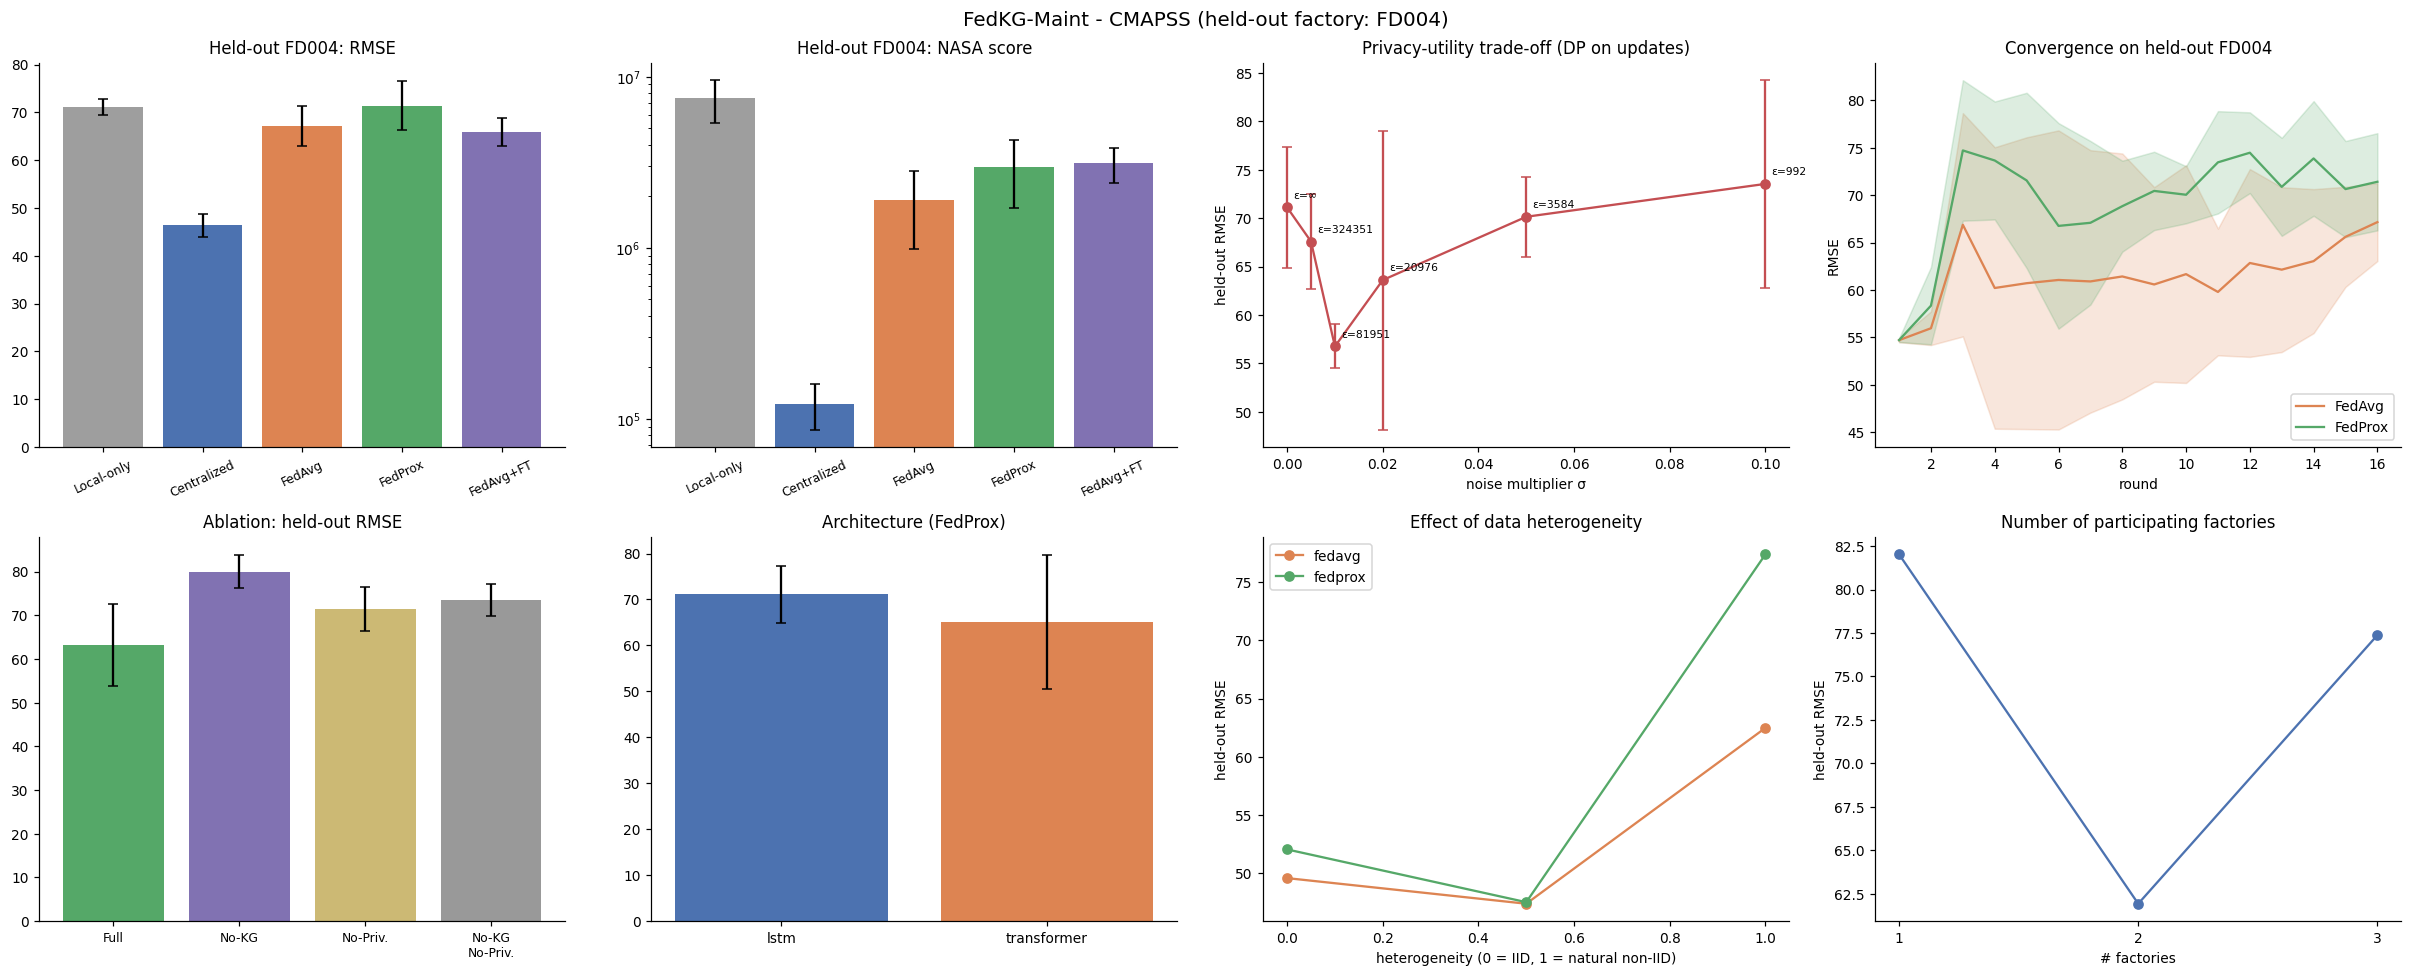

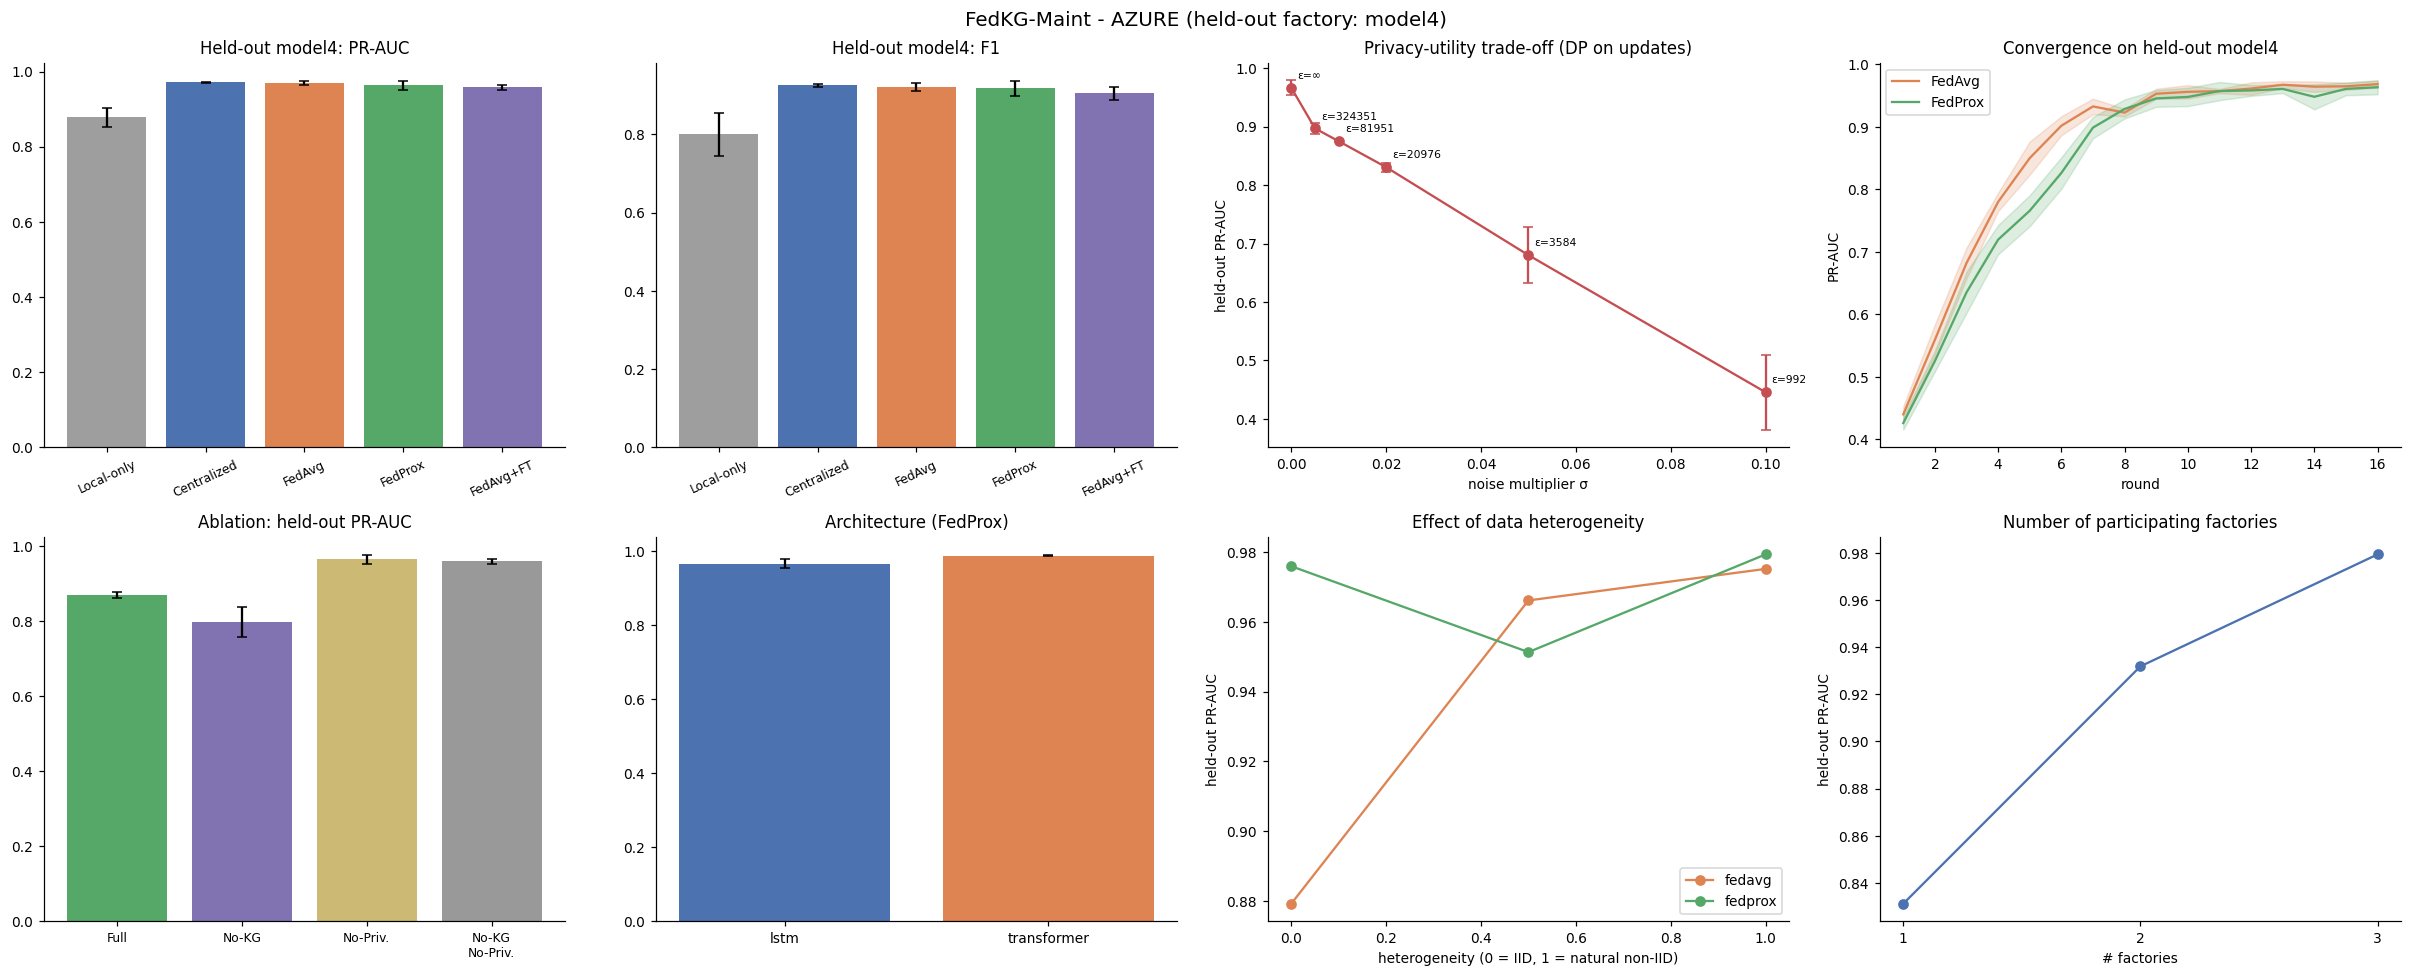

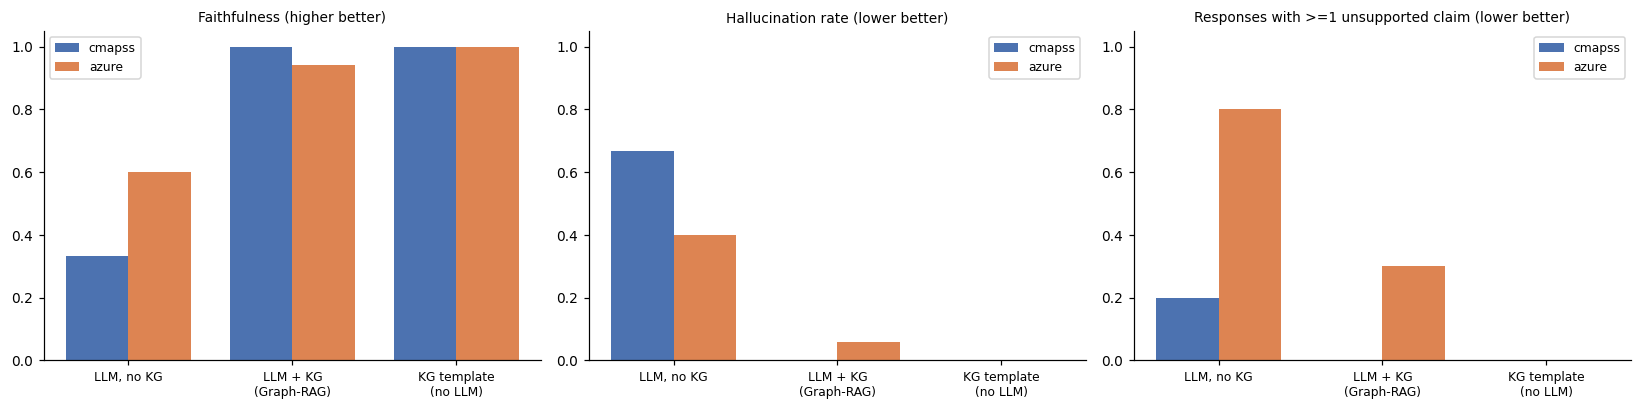


Saved figures and CSVs to /content/outputs:
  ['ablation_azure.csv', 'ablation_cmapss.csv', 'architecture_azure.csv', 'architecture_cmapss.csv', 'dashboard_azure.png', 'dashboard_cmapss.png', 'dp_tradeoff_azure.csv', 'dp_tradeoff_cmapss.csv', 'explanation_quality.csv', 'explanations.csv', 'explanations.png', 'factories_azure.csv', 'factories_cmapss.csv', 'heterogeneity_azure.csv', 'heterogeneity_cmapss.csv', 'human_eval_key.csv', 'human_eval_sheet.csv', 'methods_azure.csv', 'methods_cmapss.csv', 'ontology.json', 'significance_tests.csv']

Limitations to discuss: (1) per-factory min-max scaling mixes the 6 operating regimes of FD002/FD004; (2) C-MAPSS fault-mode rules are domain priors, not learned;
(3) explanation checks are entity-level, not full claim verification, and the human evaluation needs real raters; (4) few seeds -> low statistical power;
(5) client-side DP with 3 clients gives large formal epsilons; secure aggregation / central DP would be the next step; (6) Azure factorie

In [8]:
OUT = CFG['out_dir']; plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
COL = {'Local-only': '#9e9e9e', 'Centralized': '#4c72b0', 'FedAvg': '#dd8452', 'FedProx': '#55a868', 'FedAvg+FT': '#8172b2'}
ABL = {'Full FedKG-Maint': dict(use_kg=True, sigma=CFG['dp_sigma_full']), 'No-KG': dict(use_kg=False, sigma=CFG['dp_sigma_full']),
       'No-Privacy': dict(use_kg=True, sigma=0.0), 'No-KG & No-Privacy': dict(use_kg=False, sigma=0.0)}
ABL_VALS, ABL_DF, ARCH_DF, HET_DF, K_DF, STAT_ROWS = {}, {}, {}, {}, {}, []

def paired(a, b):
    if len(a) < 2: return float('nan')
    return float(stats.ttest_rel(a, b).pvalue) if np.std(np.array(a) - np.array(b)) > 0 else float('nan')

for task in TASK:
    T = TASK[task]; held = T['held']; m1, m2 = T['names']; seeds = CFG['seeds']; t0 = time.time()
    # ---------------- A) ablations: Full vs No-KG vs No-Privacy (FedProx) over all seeds ----------------
    runs = {n: [fed_train(task, 'fedprox', s, **c) for s in seeds] for n, c in ABL.items()}
    ABL_VALS[task] = {n: np.array([r['metrics'][held][0] for r in rs]) for n, rs in runs.items()}; rows = []
    for n, rs in runs.items():
        v1 = ABL_VALS[task][n]; v2 = np.array([r['metrics'][held][1] for r in rs])
        rows.append({'configuration': n, f'held-out {m1}': f'{v1.mean():.3f} ± {v1.std():.3f}', f'held-out {m2}': f'{v2.mean():.3f} ± {v2.std():.3f}',
                     'paired t-test p vs Full': '-' if n.startswith('Full') else f"{paired(ABL_VALS[task]['Full FedKG-Maint'], v1):.3f}"})
    ABL_DF[task] = pd.DataFrame(rows); print(f"\n=== [{task.upper()}] ablation (held-out {held}, FedProx, {len(seeds)} seeds) ===\n" + ABL_DF[task].to_string(index=False))
    # ---------------- B) method significance tests on the held-out factory ----------------
    g = lambda m: [RESULTS[task][s][m][held][0] for s in seeds]
    for a_, b_ in [('FedProx', 'Local-only'), ('FedAvg', 'Local-only'), ('FedProx', 'FedAvg'), ('FedAvg+FT', 'FedAvg'), ('FedProx', 'Centralized')]:
        STAT_ROWS.append(dict(task=task, comparison=f'{a_} vs {b_}', mean_diff=float(np.mean(g(a_)) - np.mean(g(b_))), p_value=paired(g(a_), g(b_))))
    # ---------------- C) architecture: LSTM vs Transformer ----------------
    rows = []
    for arch in ['lstm', 'transformer']:
        rs = [fed_train(task, 'fedprox', s, True, 0.0, arch=arch) for s in seeds[:CFG['arch_seeds']]]; v = [r['metrics'][held][0] for r in rs]
        rows.append(dict(architecture=arch, params=rs[0]['n_params'], **{f'held-out {m1}': np.mean(v), 'std': np.std(v)}))
    ARCH_DF[task] = pd.DataFrame(rows); print(f"\n[{task}] architecture comparison (FedProx, no DP):\n" + ARCH_DF[task].round(3).to_string(index=False))
    # ---------------- D) degree of data heterogeneity (0 = IID mixing, 1 = natural non-IID) ----------------
    rows = []
    for het in CFG['het_levels']:
        for strat in ['fedavg', 'fedprox']:
            v = [fed_train(task, strat, s, True, 0.0, het=het)['metrics'][held][0] for s in seeds[:CFG['het_seeds']]]; rows.append(dict(heterogeneity=het, strategy=strat, value=np.mean(v)))
    HET_DF[task] = pd.DataFrame(rows); print(f"\n[{task}] heterogeneity sweep (held-out {m1}; heterogeneity 1.0 = natural non-IID):\n" + HET_DF[task].round(3).to_string(index=False))
    # ---------------- E) number of participating factories + communication ----------------
    rows = []
    for k in range(1, len(T['train']) + 1):
        r = fed_train(task, 'fedprox', seeds[0], True, 0.0, clients=T['train'][:k]); rows.append(dict(factories=k, value=r['metrics'][held][0], comm_MB=r['comm_mb']))
    K_DF[task] = pd.DataFrame(rows); print(f"\n[{task}] number of factories vs held-out {m1} and communication:\n" + K_DF[task].round(3).to_string(index=False)); print(f"({time.time() - t0:.0f}s)")

ST = pd.DataFrame(STAT_ROWS); print("\n=== Paired t-tests across seeds on the held-out factory (primary metric) ===\n" + ST.round(4).to_string(index=False))
print(f"(With only {len(CFG['seeds'])} seed(s) these tests have little power; add seeds to CFG['seeds'] for publication claims. No multiple-comparison correction applied.)")

# ------------------------------- dashboard (one figure per task) -------------------------------
for task in TASK:
    T = TASK[task]; held = T['held']; m1, m2 = T['names']; seeds = CFG['seeds']; fig, ax = plt.subplots(2, 4, figsize=(22, 9)); ax = ax.ravel()
    ho1 = {m: [RESULTS[task][s][m][held][0] for s in seeds] for m in METHODS}; ho2 = {m: [RESULTS[task][s][m][held][1] for s in seeds] for m in METHODS}
    for a, h, nm in [(ax[0], ho1, m1), (ax[1], ho2, m2)]:
        a.bar(range(len(METHODS)), [np.mean(h[m]) for m in METHODS], yerr=[np.std(h[m]) for m in METHODS], color=[COL[m] for m in METHODS], capsize=3)
        a.set_xticks(range(len(METHODS))); a.set_xticklabels(METHODS, rotation=25, fontsize=8); a.set_title(f'Held-out {held}: {nm}')
    if task == 'cmapss': ax[1].set_yscale('log')
    d = DP_DF[task]; ax[2].errorbar(d.noise_multiplier, d.heldout_primary, yerr=d.heldout_primary_std, marker='o', color='#c44e52', capsize=3)
    for _, r in d.iterrows(): ax[2].annotate('ε=∞' if np.isinf(r.epsilon) else f'ε={r.epsilon:.0f}', (r.noise_multiplier, r.heldout_primary), textcoords='offset points', xytext=(4, 6), fontsize=7)
    ax[2].set_title('Privacy-utility trade-off (DP on updates)'); ax[2].set_xlabel('noise multiplier σ'); ax[2].set_ylabel(f'held-out {m1}')
    for nm, key in [('FedAvg', 'fedavg'), ('FedProx', 'fedprox')]:
        h = np.array([fed_train(task, key, s)['history'] for s in seeds]); x = np.arange(1, h.shape[1] + 1)
        ax[3].plot(x, h.mean(0), label=nm, color=COL[nm]); ax[3].fill_between(x, h.mean(0) - h.std(0), h.mean(0) + h.std(0), alpha=.2, color=COL[nm])
    ax[3].set_title(f'Convergence on held-out {held}'); ax[3].set_xlabel('round'); ax[3].set_ylabel(m1); ax[3].legend()
    nm_ = list(ABL); ax[4].bar(range(4), [ABL_VALS[task][n].mean() for n in nm_], yerr=[ABL_VALS[task][n].std() for n in nm_], capsize=3, color=['#55a868', '#8172b2', '#ccb974', '#999999'])
    ax[4].set_xticks(range(4)); ax[4].set_xticklabels(['Full', 'No-KG', 'No-Priv.', 'No-KG\nNo-Priv.'], fontsize=8); ax[4].set_title(f'Ablation: held-out {m1}')
    a_ = ARCH_DF[task]; ax[5].bar(a_.architecture, a_[f'held-out {m1}'], yerr=a_['std'], capsize=3, color=['#4c72b0', '#dd8452']); ax[5].set_title('Architecture (FedProx)')
    h_ = HET_DF[task]
    for strat in ['fedavg', 'fedprox']: q = h_[h_.strategy == strat]; ax[6].plot(q.heterogeneity, q.value, marker='o', label=strat, color=COL['FedAvg' if strat == 'fedavg' else 'FedProx'])
    ax[6].set_title('Effect of data heterogeneity'); ax[6].set_xlabel('heterogeneity (0 = IID, 1 = natural non-IID)'); ax[6].set_ylabel(f'held-out {m1}'); ax[6].legend()
    k_ = K_DF[task]; ax[7].plot(k_.factories, k_.value, marker='o', color='#4c72b0'); ax[7].set_xticks(k_.factories); ax[7].set_title('Number of participating factories'); ax[7].set_xlabel('# factories'); ax[7].set_ylabel(f'held-out {m1}')
    fig.suptitle(f'FedKG-Maint - {task.upper()} (held-out factory: {held})', fontsize=13); plt.tight_layout(); plt.savefig(os.path.join(OUT, f'dashboard_{task}.png'), dpi=200, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8)); modes = ['without_KG', 'with_KG', 'no_LLM_template']; lab = ['LLM, no KG', 'LLM + KG\n(Graph-RAG)', 'KG template\n(no LLM)']; w = 0.38
for a, (c, title) in zip(ax, [('faithfulness', 'Faithfulness (higher better)'), ('hallucination_rate', 'Hallucination rate (lower better)'), ('has_unsupported', 'Responses with >=1 unsupported claim (lower better)')]):
    for j, dom in enumerate(['cmapss', 'azure']):
        v = [EXPL_DF[(EXPL_DF.dataset == dom) & (EXPL_DF['mode'] == m)][c].astype(float).mean() for m in modes]
        a.bar(np.arange(3) + (j - .5) * w, np.nan_to_num(v), w, label=dom, color='#4c72b0' if j == 0 else '#dd8452')
    a.set_xticks(range(3)); a.set_xticklabels(lab, fontsize=8); a.set_ylim(0, 1.05); a.set_title(title, fontsize=9); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'explanations.png'), dpi=200, bbox_inches='tight'); plt.show()

# ------------------------------- export + limitations -------------------------------
for task in TASK:
    summarize(task, RESULTS[task]).to_csv(os.path.join(OUT, f'methods_{task}.csv'), index=False); ABL_DF[task].to_csv(os.path.join(OUT, f'ablation_{task}.csv'), index=False)
    ARCH_DF[task].to_csv(os.path.join(OUT, f'architecture_{task}.csv'), index=False); HET_DF[task].to_csv(os.path.join(OUT, f'heterogeneity_{task}.csv'), index=False); K_DF[task].to_csv(os.path.join(OUT, f'factories_{task}.csv'), index=False)
ST.to_csv(os.path.join(OUT, 'significance_tests.csv'), index=False); AGG.to_csv(os.path.join(OUT, 'explanation_quality.csv'))
print(f"\nSaved figures and CSVs to {OUT}:\n  {sorted(os.listdir(OUT))}")
print("\nLimitations to discuss: (1) per-factory min-max scaling mixes the 6 operating regimes of FD002/FD004; (2) C-MAPSS fault-mode rules are domain priors, not learned;")
print("(3) explanation checks are entity-level, not full claim verification, and the human evaluation needs real raters; (4) few seeds -> low statistical power;")
print("(5) client-side DP with 3 clients gives large formal epsilons; secure aggregation / central DP would be the next step; (6) Azure factories are machine models, which are only mildly non-IID.")
if SYNTHETIC_CMAPSS: print("(!) THIS RUN USED SYNTHETIC C-MAPSS-LIKE DATA - rerun with network access to the S3 mirror for real results.")
if AZURE_SYNTHETIC: print("(!) THIS RUN USED SYNTHETIC AZURE-STYLE DATA - upload the 5 PdM_*.csv files to %s for real results." % AZ_DIR)
if CFG['llm_backend'] == 'mock': print("(!) THE LLM BACKEND WAS 'mock' - explanation metrics are a pipeline test only.")
free_mem()

In [9]:
!pip install -q gradio pyvis

import os
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from pyvis.network import Network
import gradio as gr

# ==============================================================================
# 1. Interactive Knowledge Graph Visualizer (PyVis)
# ==============================================================================
def render_pyvis_kg(dataset_choice, factory_choice):
    """Converts local NetworkX graph to an interactive PyVis HTML widget."""
    graphs = KGS if dataset_choice == 'C-MAPSS' else AZ_KGS
    if factory_choice not in graphs:
        factory_choice = list(graphs.keys())[0]

    G = graphs[factory_choice]
    net = Network(height="500px", width="100%", directed=True, notebook=True, cdn_resources='remote')

    # Color palette by entity type
    color_map = {
        'Machine': '#97C2FC',
        'Component': '#FB7E81',
        'Sensor': '#FFFF00',
        'ErrorCode': '#FFA500',
        'FailureMode': '#7BE141',
        'Action': '#EB7DF4'
    }

    for node, data in G.nodes(data=True):
        ntype = data.get('type', 'Unknown')
        color = color_map.get(ntype, '#CCCCCC')
        label = f"{node}\n({ntype})" if ntype in ['FailureMode', 'Component', 'Action'] else node
        net.add_node(node, label=label, title=f"Type: {ntype}", color=color, shape="ellipse" if ntype == 'Sensor' else "box")

    for u, v, data in G.edges(data=True):
        rel = data.get('rel', '')
        title_str = ", ".join([f"{k}={round(val, 2) if isinstance(val, float) else val}" for k, val in data.items() if k != 'rel'])
        net.add_edge(u, v, label=rel, title=title_str, arrows="to")

    net.toggle_physics(True)
    html_path = "/content/outputs/interactive_kg.html"
    net.save_graph(html_path)

    with open(html_path, 'r', encoding='utf-8') as f:
        html_content = f.read()
    return html_content

# ==============================================================================
# 2. Telemetry & Degradation Inspector
# ==============================================================================
def plot_machine_telemetry(dataset_choice, factory_choice, machine_index):
    """Plots sensor time series for a selected machine instance."""
    fig, ax = plt.subplots(figsize=(10, 3.5), dpi=100)

    if dataset_choice == 'C-MAPSS':
        f_data = FAC.get(factory_choice, FAC['FD001'])
        idx = min(int(machine_index), f_data['Xte'].shape[0] - 1)
        # Plot top 4 sensors from raw feature window
        window_data = f_data['Xte'][idx, :, :4]
        for col in range(window_data.shape[1]):
            ax.plot(window_data[:, col], label=f"Sensor {KEEP[col] if col < len(KEEP) else col}")
        ax.set_title(f"C-MAPSS [{factory_choice}] - Test Window ID {idx} (True RUL: {f_data['yte'][idx]:.0f} cycles)")
        ax.set_xlabel("Time Steps (30-cycle window)")
        ax.set_ylabel("Scaled Telemetry")
    else:
        f_data = AZF.get(factory_choice, AZF['model1'])
        idx = min(int(machine_index), f_data['Xte'].shape[0] - 1)
        window_data = f_data['Xte'][idx, :, :4]
        for i, s_name in enumerate(AZ_SENS):
            ax.plot(window_data[:, i], label=s_name)
        ax.set_title(f"Azure PdM [{factory_choice}] - Test Window ID {idx} (Failure Alert: {f_data['yte'][idx]:.0f})")
        ax.set_xlabel("Time Steps (24-hour window)")
        ax.set_ylabel("Standardized Z-Score")

    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    return fig

# ==============================================================================
# 3. Grounded Explanation Inspector
# ==============================================================================
def inspect_explanation(sample_id):
    """Loads saved explanation comparisons from outputs directory."""
    csv_path = os.path.join(CFG['out_dir'], 'explanations.csv')
    if not os.path.exists(csv_path):
        return "No explanations output found.", "Please run Cell 6 first.", "N/A"

    df = pd.read_csv(csv_path)
    if df.empty:
        return "Explanations CSV is empty.", "", ""

    sample_id = int(sample_id) % len(df)
    row = df.iloc[sample_id]

    retrieved_facts = str(row.get('retrieved_facts', 'No graph facts retrieved.'))
    with_kg = str(row.get('explanation_with_KG', 'N/A'))
    without_kg = str(row.get('explanation_without_KG', 'N/A'))

    meta_info = f"**Dataset:** {row.get('dataset', 'N/A')} | **Factory:** {row.get('factory', 'N/A')} | **Predicted RUL/Risk:** {row.get('prediction', 'N/A')} | **Actual:** {row.get('true_label', 'N/A')}"
    return meta_info, retrieved_facts, with_kg, without_kg

# ==============================================================================
# 4. Gradio UI Layout
# ==============================================================================
with gr.Blocks(title="FedKG-Maint Industrial Control Center", theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🛠️ FedKG-Maint: Federated Knowledge Graph Control Center")
    gr.Markdown("Interactive diagnostic dashboard for federated predictive maintenance and grounded LLM explanations.")

    with gr.Tab("🕸️ Interactive Knowledge Graph"):
        gr.Markdown("Explore local Knowledge Graphs constructed strictly on-site at each factory node.")
        with gr.Row():
            ds_dropdown = gr.Dropdown(choices=['C-MAPSS', 'Azure'], value='C-MAPSS', label="Select Dataset")
            fac_dropdown = gr.Dropdown(choices=['FD001', 'FD002', 'FD003', 'FD004'], value='FD001', label="Select Factory Node")
            render_btn = gr.Button("Render Knowledge Graph", variant="primary")

        kg_html = gr.HTML(label="Interactive PyVis Graph Visualization")

        def update_factories(ds):
            choices = ['FD001', 'FD002', 'FD003', 'FD004'] if ds == 'C-MAPSS' else ['model1', 'model2', 'model3', 'model4']
            return gr.Dropdown(choices=choices, value=choices[0])

        ds_dropdown.change(update_factories, inputs=[ds_dropdown], outputs=[fac_dropdown])
        render_btn.click(render_pyvis_kg, inputs=[ds_dropdown, fac_dropdown], outputs=[kg_html])

    with gr.Tab("📈 Telemetry & Health Monitoring"):
        gr.Markdown("Inspect real-time sensor streams and local predictive model windows.")
        with gr.Row():
            t_ds = gr.Dropdown(choices=['C-MAPSS', 'Azure'], value='C-MAPSS', label="Dataset")
            t_fac = gr.Dropdown(choices=['FD001', 'FD002', 'FD003', 'FD004'], value='FD001', label="Factory")
            t_idx = gr.Number(value=0, label="Machine Window Index", precision=0)
            plot_btn = gr.Button("Plot Telemetry Window", variant="primary")

        telemetry_plot = gr.Plot(label="Sensor Streams")
        plot_btn.click(plot_machine_telemetry, inputs=[t_ds, t_fac, t_idx], outputs=[telemetry_plot])

    with gr.Tab("🤖 LLM Explanation & Grounding Inspector"):
        gr.Markdown("Compare Knowledge Graph-grounded LLM maintenance tickets against ungrounded baselines.")
        with gr.Row():
            sample_slider = gr.Slider(minimum=0, maximum=19, step=1, value=0, label="Select Explanation Sample ID")
            inspect_btn = gr.Button("Inspect Sample Ticket", variant="primary")

        meta_out = gr.Markdown()
        facts_out = gr.Textbox(label="Retrieved Local Knowledge Graph Triples", lines=6)

        with gr.Row():
            with_kg_out = gr.Markdown(label="✅ With Knowledge Graph Grounding")
            without_kg_out = gr.Markdown(label="❌ Without Knowledge Graph Grounding")

        inspect_btn.click(inspect_explanation, inputs=[sample_slider], outputs=[meta_out, facts_out, with_kg_out, without_kg_out])

# Launch inline inside Google Colab
demo.launch(inline=True, share=True, debug=False)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 66.1 MB/s eta 0:00:00
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ef887d0516b5f0c43f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
